# Recovery of OCT Classifier Predictions from Decision-Based Attacks: Five Perturbation Generators and Six Classical Denoisers

## 1. Study overview and data sources

**Research question.** How do recovery rates and relative denoiser performance vary across five perturbation-generator configurations (Perlin, Gabor, BICU, BILI, CLUSTER)?

**Design.**
- **Classifier:** fine-tuned InceptionV3, run v2.1. Its baseline performance is reported on the full 1,000-image Kermany OCT test set (250 per class: CNV, DME, DRUSEN, NORMAL).
- **Attacks:** BO-DBA, a hard-label black-box attack that searches the parameters of a perturbation generator with Bayesian optimization. Five generator configurations are used, each with seed 42 and a nominal budget of 200 queries.
- **Images attacked:** two patient-disjoint cohorts of 240 images, one image per patient (cohort A and cohort B), 120 per class in total.
- **Denoisers:** six classical denoisers (Gaussian, Median, Bilateral, Non-Local Means, Morphological Opening, and Average), applied to each attacked image and to all 1,000 clean test images.

**Evaluation pipeline.** All attack results come from a revised pipeline that evaluates floating-point arrays. The attacked image is clipped to [0, 1] and saved as a float32 `.npy` array; the adversarial prediction, the denoiser input and the distortion measures all use that array (Section 4). Attack results from the earlier PNG-based pipeline are not used. Despite "PNG" in some file names, every attack file passes the revised-pipeline check in Section 2.

**Clean-image cost.** The clean cost uses the earlier evaluation of all 1,000 test images, which stored filter outputs as 8-bit PNG files. A clean test image is already exactly 8-bit, so the two pipelines can differ only through rounding of the filter output. Section 5 measures that difference on the 480 cohort images, which both pipelines evaluated.

**Scope.** The attacks are non-adaptive: they target the undefended classifier and never see a denoiser. Results describe *recovery from these attacks*, not adversarial robustness. The generator configurations differ at once in search dimensionality, achieved distortion, and recorded query and stopping behavior, so these data cannot isolate a causal effect of perturbation structure or frequency.

**Analysis history.** These analyses were not pre-registered. They were developed iteratively on earlier runs, and the BILI and CLUSTER configurations were added after the Perlin, Gabor and BICU results had been analysed. All five configurations were then rerun under the revised pipeline, and only those reruns are analysed here. The six Cochran's Q tests and the 30 McNemar tests are the main inferential tests, each corrected for multiplicity within its stated family. Everything labelled *exploratory* is descriptive support.

**Data files.** The files are in the repository's `data/` folder, and the notebook finds them automatically. Every number is recomputed from them when the notebook runs.

| Key | Default files (cohort A, cohort B) | Contents |
|---|---|---|
| `test_predictions` | `test_predictions_1.csv` | classifier predictions on the 1,000 test images (reference file) |
| `run_info` | `run_info_1.json` | training record of the classifier |
| `clean` | `New_All_Clean_OCT_2_.xlsx` | six denoisers applied to the 1,000 clean test images (earlier PNG-based evaluation) |
| `perlin` | `240_PNG_Perlin.xlsx`, `More_240_PNG_Perlin_1.xlsx` | 240 images per cohort; 14 conditions per image (original, adversarial, six attack-denoised, six clean-denoised) |
| `gabor` | `240_PNG_Gabor.xlsx`, `More_240_PNG_Gabor.xlsx` | as above |
| `BICU` | `240_PNG_BICU.xlsx`, `More_240_PNG_BICU.xlsx` | as above |
| `BILI` | `240_PNG_BILI.xlsx`, `More_240_PNG_BILI.xlsx` | as above |
| `CLUSTER` | `240_PNG_CLUSTER.xlsx`, `More_240_PNG_CLUSTER.xlsx` | as above |

**Outputs.** Figures (PDF and 300-dpi PNG), tables (CSV and LaTeX) and a manifest are written to `OUT_DIR`.


### Running in Google Colab

Run the next cell first. In Colab it clones this repository (including the `data/` folder) and installs the required packages; when the notebook runs locally from the repository folder, it does nothing. For a **private** repository, add a GitHub token as a Colab secret named `GITHUB_TOKEN` (key icon in the left sidebar) and allow this notebook to access it.

In [1]:
import os, sys
GITHUB_USER = "thitimas"                  # GitHub account that owns the repository
REPO_NAME   = "oct-denoising-study"

if "google.colab" in sys.modules:
    repo_dir = f"/content/{REPO_NAME}"
    if not os.path.isdir(repo_dir):
        url = f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git"
        try:                                    # private repository: token stored in Colab Secrets as GITHUB_TOKEN
            from google.colab import userdata
            url = url.replace("https://", f"https://{userdata.get('GITHUB_TOKEN')}@")
        except Exception:
            pass                                # public repository: no token needed
        !git clone -q {url} {repo_dir}
    %cd {repo_dir}
    !pip -q install -r requirements.txt
else:
    print("Not running in Colab: using the local repository folder.")

Not running in Colab: using the local repository folder.


In [2]:
import os, io, re, sys, json, zipfile, platform, warnings, urllib.request
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from matplotlib.ticker import FixedLocator, ScalarFormatter
import seaborn as sns
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar, cochrans_q
from statsmodels.stats.multitest import multipletests
# Warnings are not suppressed globally; GEE warnings are captured and reported in Section 11.

# ------------------------------ configuration ------------------------------
DATA_DIR = next((p for p in ("data", "../data", ".") if os.path.exists(os.path.join(p, "test_predictions_1.csv"))), "data")   # repository data folder
FILES = {
    "test_predictions": "test_predictions_1.csv",
    "run_info":         "run_info_1.json",
    "clean":            "New_All_Clean_OCT_2_.xlsx",      # 1,000 clean test images, earlier PNG-based evaluation
    "perlin":  ("240_PNG_Perlin.xlsx",  "More_240_PNG_Perlin_1.xlsx"),   # (cohort A, cohort B)
    "gabor":   ("240_PNG_Gabor.xlsx",   "More_240_PNG_Gabor.xlsx"),
    "BICU":    ("240_PNG_BICU.xlsx",    "More_240_PNG_BICU.xlsx"),
    "BILI":    ("240_PNG_BILI.xlsx",    "More_240_PNG_BILI.xlsx"),
    "CLUSTER": ("240_PNG_CLUSTER.xlsx", "More_240_PNG_CLUSTER.xlsx"),
}
OUT_DIR = "outputs"
FIG_DIR, TAB_DIR = f"{OUT_DIR}/figures", f"{OUT_DIR}/tables"
SEED, B_BOOT = 42, 3000

# ------------------------------ study definitions ------------------------------
CLASSES    = ["CNV", "DME", "DRUSEN", "NORMAL"]
DENOISERS  = ["Gaussian", "Median", "Bilateral", "Non-Local Means", "Morphological Opening", "Average"]   # display order everywhere
DEN_LABEL  = {"Gaussian": "Gaussian", "Median": "Median", "Bilateral": "Bilateral", "Non-Local Means": "NLM",
              "Morphological Opening": "Morph. opening", "Average": "Average"}
GENERATORS = ["perlin", "gabor", "BICU", "BILI", "CLUSTER"]
GEN_LABEL  = {"perlin": "Perlin", "gabor": "Gabor", "BICU": "BICU", "BILI": "BILI", "CLUSTER": "CLUSTER"}
GEN_COLOR  = {"perlin": "#4C72B0", "gabor": "#DD8452", "BICU": "#55A868", "BILI": "#8172B3", "CLUSTER": "#C44E52"}
GEN_DIM    = {"perlin": 3, "gabor": 6, "BICU": 48, "BILI": 48, "CLUSTER": 48}   # search parameters per configuration (BODBA.py)
COHORTS    = ["A", "B"]
CONDITIONS = ["Original", "Adversarial"] + [f"{m}-Attack" for m in DENOISERS] + [f"{m}-Clean" for m in DENOISERS]
CLEAN_CONDITIONS = ["Original"] + [f"{m}-Clean" for m in DENOISERS]
SELECTED   = ["Morphological Opening", "Non-Local Means", "Gaussian"]   # denoisers for the pairwise generator comparisons
T16, T8, ONE_LEVEL = 16 / 255, 8 / 255, 1 / 255
NOMINAL_BUDGET, EXPECTED_SEED, LOW_Q, IMG_SIZE = 200, 42, 190, 224
N_VALUES = IMG_SIZE * IMG_SIZE * 3          # pixel values per image (224 x 224 x 3)
EXPECTED_VALID = {"A": 222, "B": 229}   # eligible, successfully attacked images reported for this study

# ------------------------------ figure style (sized for a two-column IEEE paper) ------------------------------
COL_W, FULL_W = 3.5, 7.16   # inches
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
                     "legend.fontsize": 7, "axes.titleweight": "bold", "figure.dpi": 150,
                     "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.bbox": "tight", "savefig.pad_inches": 0.03,
                     "axes.linewidth": 0.6, "grid.linewidth": 0.4, "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                     "xtick.major.size": 2.5, "ytick.major.size": 2.5, "patch.linewidth": 0.5})
G_FMT = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}")      # plain tick labels: 1, 2, 0.5
DEN_COLOR = dict(zip(DENOISERS, sns.color_palette("Dark2", len(DENOISERS))))
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(TAB_DIR, exist_ok=True)

# ------------------------------ helpers ------------------------------
MANIFEST, COMPLETED = [], []
def mark_done(section): COMPLETED.append(section)

def read_table(name):
    p = f"{DATA_DIR}/{name}"
    return pd.read_csv(p) if name.lower().endswith(".csv") else pd.read_excel(p)

def read_json(name):
    p = f"{DATA_DIR}/{name}"
    if p.startswith("http"): return json.load(urllib.request.urlopen(p))
    with open(p) as f: return json.load(f)

def fmt_p(p):
    """Very small p-values in scientific notation; never prints 0.000."""
    if p is None or pd.isna(p): return "n/a"
    return f"{p:.1e}" if p < 0.001 else f"{p:.3f}"

def fmt_ci(x, lo, hi, d=1): return f"{x:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]"

def flag_to_bool(s):
    """'Y' -> True, 'N' -> False, anything else -> missing. A missing flag is never counted as success or recovery."""
    return s.map({"Y": True, "N": False}).astype("boolean")

def strat_boot(X, cohort, B=B_BOOT, seed=SEED):
    """Paired patient bootstrap for the attack cohorts (one image per patient).
    Each sampled patient keeps all of its outcomes (pairing across generators and denoisers is preserved).
    Resampling is done within cohort A and within cohort B; the pooled estimate keeps the original cohort weights."""
    rng = np.random.default_rng(seed); X = np.asarray(X, float); cohort = np.asarray(cohort)
    ia, ib = np.where(cohort == "A")[0], np.where(cohort == "B")[0]
    wa = rng.multinomial(len(ia), np.full(len(ia), 1 / len(ia)), size=B)
    wb = rng.multinomial(len(ib), np.full(len(ib), 1 / len(ib)), size=B)
    sa, sb = wa @ X[ia], wb @ X[ib]
    return {"A": sa / len(ia), "B": sb / len(ib), "pooled": (sa + sb) / (len(ia) + len(ib))}

def cluster_boot(X, groups, B=B_BOOT, seed=SEED):
    """Patient-clustered bootstrap for the clean set (patients can contribute several images). Returns (B, k) means."""
    X = np.asarray(X, float); codes, uniq = pd.factorize(pd.Series(np.asarray(groups).astype(str)))
    sums = np.zeros((len(uniq), X.shape[1])); np.add.at(sums, codes, X)
    cnts = np.bincount(codes, minlength=len(uniq)).astype(float)
    w = np.random.default_rng(seed).multinomial(len(uniq), np.full(len(uniq), 1 / len(uniq)), size=B)
    return (w @ sums) / (w @ cnts)[:, None]

def pct_ci(dist): return np.percentile(dist, [2.5, 97.5], axis=0)

def export_fig(fig, name, description):
    """Save one figure as vector PDF (TrueType fonts embedded) and 300-dpi PNG, and record it in the manifest."""
    for ext in ("pdf", "png"):
        path = f"{FIG_DIR}/{name}.{ext}"
        fig.savefig(path, dpi=300)
        MANIFEST.append({"file": path, "type": f"figure ({ext})", "description": description})
    plt.show()

def _tex(s):
    s = str(s)
    for a, b in [("&", r"\&"), ("%", r"\%"), ("_", r"\_"), ("#", r"\#")]: s = s.replace(a, b)
    s = s.replace("Linf", r"$L_\infty$").replace("<=", r"$\le$").replace(">=", r"$\ge$")
    return s.replace("<", r"$<$").replace(">", r"$>$")

def _tex_p(p):
    if pd.isna(p): return "n/a"
    if p < 0.001:
        m, e = f"{p:.1e}".split("e"); return rf"${m}\times10^{{{int(e)}}}$"
    return f"{p:.3f}"

def export_table(df, name, caption, p_cols=(), description=None, index=True, latex_df=None, wide=None):
    """Write the full table as CSV, and a booktabs LaTeX table (latex_df, if given, is a compact layout for the paper).
    wide=True uses a full-width table* environment for a two-column paper."""
    df.to_csv(f"{TAB_DIR}/{name}.csv", index=index)
    df = latex_df if latex_df is not None else df
    cols = list(df.columns)
    env = ("table*" if wide else "table") if wide is not None else ("table*" if len(cols) + (1 if index else 0) > 6 else "table")
    lines = [rf"\begin{{{env}}}[t]", r"\centering", rf"\caption{{{_tex(caption)}}}", rf"\label{{tab:{name}}}", r"\footnotesize", r"\setlength{\tabcolsep}{4pt}",
             r"\begin{tabular}{" + ("l" if index else "") + "r" * len(cols) + "}", r"\toprule",
             " & ".join(([_tex(df.index.name or "")] if index else []) + [_tex(c) for c in cols]) + r" \\", r"\midrule"]
    for i in range(len(df)):
        cells = [_tex(df.index[i])] if index else []
        for j, c in enumerate(cols):
            v = df.iloc[i, j]                      # positional access keeps each column's dtype
            if c in p_cols: cells.append(_tex_p(v))
            elif isinstance(v, (bool, np.bool_)): cells.append("yes" if v else "no")
            elif isinstance(v, (int, np.integer)): cells.append(str(v))
            elif isinstance(v, (float, np.floating)): cells.append(f"{v:.1f}")
            else: cells.append(_tex(v))
        lines.append(" & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", rf"\end{{{env}}}"]
    with open(f"{TAB_DIR}/{name}.tex", "w") as f: f.write("\n".join(lines) + "\n")
    for ext in ("csv", "tex"):
        MANIFEST.append({"file": f"{TAB_DIR}/{name}.{ext}", "type": f"table ({ext})", "description": description or caption})

print("setup complete")


setup complete


## 2. Data-integrity checks

Each check has a status: **PASS**, **FLAG** (reported, does not invalidate analyses), or **FAIL** (stops every analysis that depends on it). Later sections call `require()`, which stops with a message if a required check failed *or was never run*.

**Duplicate policy.** Any duplicated image-condition record is a FAIL, whether or not the duplicates are identical. Later steps reshape the data with `pivot`, which requires exactly one record per image and condition. Duplicates are never dropped silently.

**Missing outcomes.** A missing correctness flag is never interpreted as an attack success or a recovery.


In [3]:
CHECKS = []
def add_check(cid, name, ok, detail, affects, fail_level="FAIL"):
    CHECKS.append({"id": cid, "check": name, "status": "PASS" if ok else fail_level, "detail": detail, "affects": affects})
    return ok

def require(*ids):
    """Stop if a required check is absent or failed."""
    have = {c["id"]: c for c in CHECKS}
    absent = [i for i in ids if i not in have]
    failed = [have[i] for i in ids if i in have and have[i]["status"] == "FAIL"]
    if absent or failed:
        msg = []
        if absent: msg.append("required checks not run: " + ", ".join(absent))
        msg += [f"[{c['id']}] {c['check']}: {c['detail']}" for c in failed]
        raise RuntimeError("Stopping this analysis because of unresolved data problems:\n  " + "\n  ".join(msg))

# ---------------- reference prediction file ----------------
ref = read_table(FILES["test_predictions"]); run_info = read_json(FILES["run_info"])
ref["file"] = ref["path"].apply(os.path.basename)
add_check("R1", "reference file: 1,000 rows, one per image", ref["file"].is_unique and len(ref) == 1000,
          f"{len(ref)} rows, {ref['file'].nunique()} unique files", "everything")
pid = ref["file"].str.split("-").str[1]
add_check("R2", "reference file: patient column matches the file name", bool((ref["patient"].astype(str) == pid).all()),
          f"{int((ref['patient'].astype(str) != pid).sum())} mismatches", "patient clustering")
add_check("R3", "reference accuracy equals the training record", abs((ref["pred"] == ref["class"]).mean() - run_info["test_accuracy"]) < 1e-9,
          f"recomputed {(ref['pred'] == ref['class']).mean():.4f}; run_info {run_info['test_accuracy']:.4f}", "baseline")
ref_i = ref.set_index("file")

# ---------------- attack files ----------------
raw = {g: {coh: read_table(FILES[g][i]) for i, coh in enumerate(COHORTS)} for g in GENERATORS}

def check_attack_file(d0, g, coh):
    tag = f"{g}/{coh}"
    blank = int(d0["Run"].isna().sum()); d = d0[d0["Run"].notna()].copy()
    add_check(f"{tag}-0", f"{tag}: rows without a Run id", blank == 0, f"{blank} such rows (not used)", "this file", "FLAG")
    cnt = d.groupby(["File Name", "Processing"]).size().unstack(fill_value=0)
    unexpected = sorted(set(cnt.columns) - set(CONDITIONS)); cnt = cnt.reindex(columns=CONDITIONS, fill_value=0)
    n_dup, n_miss = int((cnt > 1).sum().sum()), int((cnt == 0).sum().sum())
    dup_kind = ""
    if n_dup:
        dd = d[d.duplicated(["File Name", "Processing"], keep=False)]
        dup_kind = " (identical)" if dd.drop(columns=["Run"]).duplicated(keep=False).all() else " (conflicting)"
    add_check(f"{tag}-1", f"{tag}: exactly one record per image and condition; all 14 conditions; none unexpected",
              n_dup == 0 and n_miss == 0 and not unexpected,
              f"{d['File Name'].nunique()} images; duplicated cells {n_dup}{dup_kind}; missing cells {n_miss}; unexpected conditions {unexpected}",
              "all analyses of this generator")
    okf = flag_to_bool(d["Correct?"]); n_na = int(okf.isna().sum())
    agree = (okf == (d["Prediction"] == d["True Label"])) | okf.isna()
    add_check(f"{tag}-2", f"{tag}: correctness flags present and equal to prediction == true label", n_na == 0 and bool(agree.all()),
              f"missing or invalid flags {n_na}; disagreements {int((~agree).sum())}", "eligibility and recovery")
    adv = d[d["Processing"] == "Adversarial"]
    req = int(d[["Prediction", "True Label"]].isna().sum().sum())
    nonfinite = int((~np.isfinite(adv[["Linf", "L2", "SSIM", "Query Used"]].astype(float))).sum().sum())
    add_check(f"{tag}-3", f"{tag}: predictions present; distortion and query values complete and finite", req == 0 and nonfinite == 0,
              f"missing predictions/labels {req}; non-finite Linf/L2/SSIM/queries {nonfinite}", "distortion and recovery")
    l2max = np.sqrt(IMG_SIZE * IMG_SIZE * 3)
    bad = int(((adv["Linf"] <= 0) | (adv["Linf"] > 1)).sum() + ((adv["L2"] < 0) | (adv["L2"] > l2max)).sum()
              + ((adv["SSIM"] < -1) | (adv["SSIM"] > 1)).sum()
              + ((adv["Query Used"] < 1) | (adv["Query Used"] > 10 * NOMINAL_BUDGET) | (adv["Query Used"] % 1 != 0)).sum())
    add_check(f"{tag}-4", f"{tag}: values within plausible ranges", bad == 0,
              f"{bad} out-of-range values (Linf in (0,1], L2 in [0,{l2max:.0f}], SSIM in [-1,1], integer queries 1-{10*NOMINAL_BUDGET})", "distortion and queries")
    sentinel = int((adv["Linf"] >= 0.999).sum())
    add_check(f"{tag}-5", f"{tag}: no failure sentinel (the search returns Linf = 1.0 when it cannot change the label)",
              sentinel == 0, f"{sentinel} records at the sentinel value", "attack success")
    sub = int((adv["Linf"] < ONE_LEVEL).sum())
    add_check(f"{tag}-6", f"{tag}: perturbations with Linf < 1/255", sub == 0,
              f"{sub} of {len(adv)}; they exist only in float arrays and would not survive 8-bit storage", "interpretation of very small attacks", "FLAG")
    meta_ok = (set(adv["Noise Generator"].astype(str).str.lower()) == {g.lower()} and set(adv["Seeds"]) == {EXPECTED_SEED}
               and set(adv["Query Budget"]) == {NOMINAL_BUDGET})
    add_check(f"{tag}-7", f"{tag}: generator label, recorded seed and nominal budget as intended", meta_ok,
              f"labels {sorted(set(adv['Noise Generator'].astype(str)))}; seeds {sorted(set(adv['Seeds']))}; budgets {sorted(set(adv['Query Budget']))}", "this generator")
    runs = sorted(d["Run"].astype(int).unique()); gaps = sorted(set(range(runs[0], runs[-1] + 1)) - set(runs))
    add_check(f"{tag}-8", f"{tag}: no skipped images (Run numbers consecutive; the batch writes no rows for an attack that finds no adversarial)",
              len(gaps) == 0, f"Run {runs[0]}-{runs[-1]}; missing Run numbers {gaps[:10]}", "attack success counts")
    psnr_rec = pd.to_numeric(adv["PSNR"].astype(str).str.replace(" dB", "", regex=False), errors="coerce")
    psnr_l2 = 20 * np.log10(np.sqrt(N_VALUES) / adv["L2"].astype(float))
    gap_db = (psnr_rec - psnr_l2).abs()
    add_check(f"{tag}-9", f"{tag}: L2 and PSNR describe the same image pair (signature of the revised pipeline)",
              bool((gap_db < 0.001).all()), f"largest |PSNR - PSNR implied by L2| = {gap_db.max():.5f} dB", "distortion measures and pipeline identity")
    return d

rows_ok = {g: {coh: check_attack_file(raw[g][coh], g, coh) for coh in COHORTS} for g in GENERATORS}

# ---------------- consistency across generators and with the reference ----------------
orig = {g: {coh: rows_ok[g][coh][rows_ok[g][coh]["Processing"] == "Original"].drop_duplicates("File Name", keep=False)
                 .set_index("File Name")[["True Label", "Prediction", "Correct?"]] for coh in COHORTS} for g in GENERATORS}
for coh in COHORTS:
    sets = [set(orig[g][coh].index) for g in GENERATORS]
    add_check(f"X1-{coh}", f"cohort {coh}: identical image set for every generator", all(s == sets[0] for s in sets),
              f"sizes {[len(s) for s in sets]}", "all paired comparisons")
    base = orig[GENERATORS[0]][coh]
    diffs = sum(int((orig[g][coh].reindex(base.index) != base).any(axis=1).sum()) for g in GENERATORS[1:])
    add_check(f"X2-{coh}", f"cohort {coh}: identical true labels, original predictions and baseline correctness across generators",
              diffs == 0, f"{diffs} image-level differences", "eligibility and pairing")
A_set, B_set = set(orig["perlin"]["A"].index), set(orig["perlin"]["B"].index)
add_check("X3", "cohort membership: A and B share no images, and each image stays in the same cohort for every generator",
          not (A_set & B_set) and all(set(orig[g]["A"].index) == A_set and set(orig[g]["B"].index) == B_set for g in GENERATORS),
          f"{len(A_set & B_set)} shared images", "cohort analyses")
pA, pB = pd.Series([f.split("-")[1] for f in A_set]), pd.Series([f.split("-")[1] for f in B_set])
add_check("X4", "one image per patient in each cohort; no patient in both cohorts", pA.is_unique and pB.is_unique and not (set(pA) & set(pB)),
          f"A {len(A_set)} images / {pA.nunique()} patients; B {len(B_set)} / {pB.nunique()}; shared patients {len(set(pA) & set(pB))}",
          "patient bootstrap")
both = pd.concat([orig["perlin"]["A"], orig["perlin"]["B"]])
miss_ref = int((~both.index.isin(ref_i.index)).sum())
ag_p = (both["Prediction"] == ref_i.reindex(both.index)["pred"]).mean(); ag_l = (both["True Label"] == ref_i.reindex(both.index)["class"]).mean()
add_check("X5", "original predictions and labels agree with the reference prediction file", miss_ref == 0 and ag_p == 1 and ag_l == 1,
          f"not in reference {miss_ref}; prediction agreement {ag_p*100:.1f}%; label agreement {ag_l*100:.1f}%", "eligibility")

# ---------------- clean file ----------------
clean0 = read_table(FILES["clean"]); blank = int(clean0["File Name"].isna().sum()); clean = clean0[clean0["File Name"].notna()].copy()
cnt = clean.groupby(["File Name", "Processing"]).size().unstack(fill_value=0)
unexpected = sorted(set(cnt.columns) - set(CLEAN_CONDITIONS)); cnt = cnt.reindex(columns=CLEAN_CONDITIONS, fill_value=0)
add_check("C1", "clean file: exactly one record per image and condition (7 conditions) for all 1,000 reference images",
          blank == 0 and int((cnt != 1).sum().sum()) == 0 and not unexpected and set(cnt.index) == set(ref_i.index),
          f"{len(cnt)} images; cells not equal to one record {int((cnt != 1).sum().sum())}; unexpected {unexpected}; blank rows {blank}", "clean-cost analyses")
cf = flag_to_bool(clean["Correct?"]); cag = (cf == (clean["Prediction"] == clean["True Label"])) | cf.isna()
add_check("C2", "clean file: correctness flags present and equal to prediction == true label", int(cf.isna().sum()) == 0 and bool(cag.all()),
          f"missing {int(cf.isna().sum())}; disagreements {int((~cag).sum())}", "clean-cost analyses")
co = clean[clean["Processing"] == "Original"].drop_duplicates("File Name", keep=False).set_index("File Name")
add_check("C3", "clean file: original predictions, labels and patient IDs agree with the reference file",
          bool((co["Prediction"] == ref_i.reindex(co.index)["pred"]).all() and (co["True Label"] == ref_i.reindex(co.index)["class"]).all()
               and (co["Patient ID"].astype(str) == ref_i.reindex(co.index)["patient"].astype(str)).all()),
          "compared image by image", "clean-cost analyses")
add_check("C4", "clean file: predictions and labels present in every record", int(clean[["Prediction", "True Label"]].isna().sum().sum()) == 0,
          f"{int(clean[['Prediction', 'True Label']].isna().sum().sum())} missing values", "clean-cost analyses")

# ---------------- clean-denoised rows: identical in every generator file? ----------------
# The clean step does not involve the attack, so each image's Original and clean-denoised rows should be the same in all five files.
if all(c["status"] != "FAIL" for c in CHECKS if c["id"].endswith("-1")):
    def clean_view(g, coh):
        d = rows_ok[g][coh]
        return d[(d["Processing"] == "Original") | d["Processing"].str.endswith("-Clean")].set_index(["File Name", "Processing"])[["Prediction", "Correct?"]]
    n_diff = n_cmp = 0
    for coh in COHORTS:
        base_v = clean_view(GENERATORS[0], coh)
        for g in GENERATORS[1:]:
            other = clean_view(g, coh).reindex(base_v.index)
            n_diff += int((other != base_v).any(axis=1).sum()); n_cmp += len(base_v)
    add_check("C5", "original and clean-denoised rows are identical across the five generator files", n_diff == 0,
              f"{n_diff} differing records of {n_cmp} compared", "clean-cost analyses")
else:
    add_check("C5", "original and clean-denoised rows are identical across the five generator files", False,
              "not evaluated because record-level checks failed", "clean-cost analyses")

checks = pd.DataFrame(CHECKS)
print("status counts:", checks["status"].value_counts().to_dict())
with pd.option_context("display.max_colwidth", 130, "display.max_rows", 200):
    display(checks[checks["status"] != "PASS"][["id", "status", "check", "detail"]] if (checks["status"] != "PASS").any() else "all checks passed")
mark_done("2")


status counts: {'PASS': 106, 'FLAG': 9}


,id,status,check,detail
9,perlin/A-6,FLAG,perlin/A: perturbations with Linf < 1/255,8 of 240; they exist only in float arrays and would not survive 8-bit storage
19,perlin/B-6,FLAG,perlin/B: perturbations with Linf < 1/255,6 of 240; they exist only in float arrays and would not survive 8-bit storage
29,gabor/A-6,FLAG,gabor/A: perturbations with Linf < 1/255,7 of 240; they exist only in float arrays and would not survive 8-bit storage
39,gabor/B-6,FLAG,gabor/B: perturbations with Linf < 1/255,8 of 240; they exist only in float arrays and would not survive 8-bit storage
49,BICU/A-6,FLAG,BICU/A: perturbations with Linf < 1/255,3 of 240; they exist only in float arrays and would not survive 8-bit storage
59,BICU/B-6,FLAG,BICU/B: perturbations with Linf < 1/255,3 of 240; they exist only in float arrays and would not survive 8-bit storage
69,BILI/A-6,FLAG,BILI/A: perturbations with Linf < 1/255,1 of 240; they exist only in float arrays and would not survive 8-bit storage
79,BILI/B-6,FLAG,BILI/B: perturbations with Linf < 1/255,2 of 240; they exist only in float arrays and would not survive 8-bit storage
89,CLUSTER/A-6,FLAG,CLUSTER/A: perturbations with Linf < 1/255,1 of 240; they exist only in float arrays and would not survive 8-bit storage


**Scope of these checks.** They establish *internal consistency* of the result files: complete and unique records, consistent images, labels, cohorts and baseline predictions across generators, and agreement with the reference prediction file. They do **not** independently validate the attack implementation, the denoiser settings, or the identity of the model checkpoint used in each run. Agreement of predictions with the reference file is consistent with the same classifier, but it is not proof of checkpoint identity. The full list of checks is in the `checks` table.


## 3. Baseline classifier performance

InceptionV3 v2.1 on the 1,000-image test set (635 patients). Intervals resample whole patients.


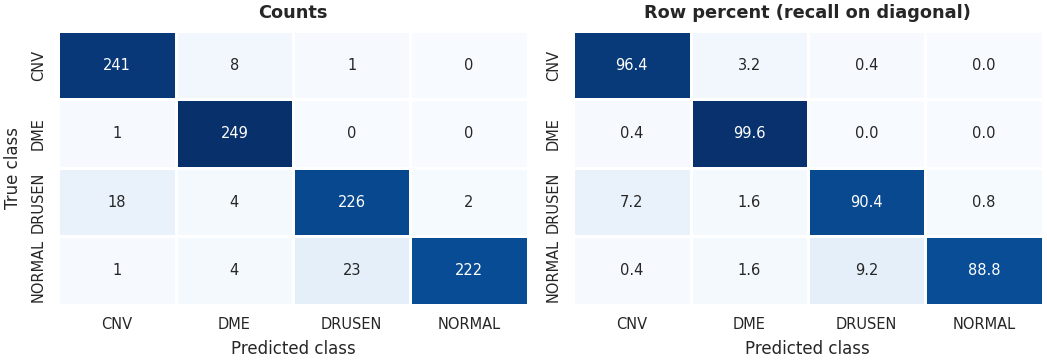

,n,Recall % [95% CI],Precision % [95% CI],F1
Class,,,,
CNV,250,"96.4 [93.6, 98.7]","92.3 [88.4, 95.6]",0.943
DME,250,"99.6 [98.7, 100.0]","94.0 [90.4, 96.9]",0.967
DRUSEN,250,"90.4 [86.7, 94.0]","90.4 [86.0, 94.2]",0.904
NORMAL,250,"88.8 [85.2, 92.1]","99.1 [97.7, 100.0]",0.937


accuracy 93.8 [92.3, 95.2] (patient-clustered bootstrap); validation accuracy in the training record: 85.1%


In [4]:
require("R1", "R2", "R3")
ref["correct"] = ref["pred"] == ref["class"]; n_test = len(ref); acc = ref["correct"].mean(); groups = ref["patient"].astype(str)
cm = pd.crosstab(ref["class"], ref["pred"]).reindex(index=CLASSES, columns=CLASSES, fill_value=0)
cm_pct = cm.div(cm.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(1, 2, figsize=(FULL_W, 2.6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0], linewidths=.5, annot_kws={"size": 7})
ax[0].set(title="Counts", xlabel="Predicted class", ylabel="True class")
sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax[1], linewidths=.5, annot_kws={"size": 7})
ax[1].set(title="Row percent (recall on diagonal)", xlabel="Predicted class", ylabel="")
plt.tight_layout()
export_fig(fig, "fig01_baseline_confusion_matrix", f"Baseline confusion matrix, InceptionV3 v2.1, 1,000 test images (accuracy {acc*100:.1f}%)")

rows = []
for c in CLASSES:
    is_c, pr_c = (ref["class"] == c).astype(float), (ref["pred"] == c).astype(float); hit = is_c * ref["correct"]
    dr = cluster_boot(np.column_stack([hit, is_c]), groups); dp = cluster_boot(np.column_stack([hit * pr_c, pr_c]), groups)
    rec, prec = cm.loc[c, c] / cm.loc[c].sum() * 100, cm.loc[c, c] / cm[c].sum() * 100
    (rlo, rhi), (plo, phi) = pct_ci(dr[:, 0] / dr[:, 1] * 100), pct_ci(dp[:, 0] / dp[:, 1] * 100)
    rows.append({"Class": c, "n": int(cm.loc[c].sum()), "Recall % [95% CI]": fmt_ci(rec, rlo, rhi),
                 "Precision % [95% CI]": fmt_ci(prec, plo, phi), "F1": round(2 * rec * prec / (rec + prec) / 100, 3)})
t1 = pd.DataFrame(rows).set_index("Class"); display(t1)
acc_lo, acc_hi = pct_ci(cluster_boot(ref[["correct"]].astype(float), groups)[:, 0] * 100)
print(f"accuracy {fmt_ci(acc*100, acc_lo, acc_hi)} (patient-clustered bootstrap); validation accuracy in the training record: {run_info['validation_accuracy']*100:.1f}%")
t1_tex = t1.rename(columns={"Recall % [95% CI]": "Recall (%)", "Precision % [95% CI]": "Precision (%)"})
t1_tex["F1"] = t1_tex["F1"].map(lambda v: f"{v:.3f}")
export_table(t1, "table1_baseline_class_metrics", "Baseline per-class performance, InceptionV3 v2.1 (1,000 test images; % with patient-clustered 95% CI).",
             latex_df=t1_tex, wide=False)
mark_done("3")


## 4. Attack characteristics

**Definitions.**
- **Eligible image:** correctly classified before any attack.
- **Successful attack (flipped):** the adversarial prediction, made on the saved float array, has a stored correctness flag of "N". Success is counted, not assumed; a missing adversarial row counts as a failure.
- **Valid attacked image:** eligible and flipped. All recovery results are conditional on baseline correctness and on a successful flip.

The search enlarges the perturbation until the label changes, so most eligible images are flipped. Under a fixed distortion constraint (for example, L∞ ≤ 16/255) only some of these flips would count as successes. The threshold shares below describe the **saved** attack outputs, not everything the optimizer might achieve with a different budget or stopping rule.

**Pipeline used for these runs** (verified in `Demo240_1.ipynb`, code cell 8, and `BODBA_237628.py`):

| Item | What the code does | Consequence |
|---|---|---|
| Candidate images | `create_distorted_image` clips every candidate to [0, 1] (`BODBA_237628.py` line 217); the notebook clips the returned image again (lines 384–388) | The attack's own decisions and the saved image use the same in-range array |
| Evaluated adversarial image | Saved as float32 `adversarial.npy` (line 406); predicted with `recognize_image("adversarial.npy")` (line 412) | Success is verified on the saved array, not assumed |
| Denoiser input | `denoiser_precision.py adversarial.npy` (lines 517–520); denoised arrays read from `.npy` (lines 78–88); predictions from `recognize_denoised()` (line 522) | Denoisers receive the evaluated array; PNGs are still written (lines 395–403) but not used |
| Distortion | L∞ and L2 computed directly from `original.npy` and `adversarial.npy` (lines 506–510); SSIM and PSNR from the same arrays (lines 471–484) | All four measures describe the evaluated pair (checked in Section 2: L2 and PSNR agree in every row) |
| Failed attacks | A failed search returns `(None, inf)` and is never stored (`BODBA_237628.py` lines 45, 237–241); if no adversarial is found, the notebook skips the image **without writing any row** (lines 336–342) | A skipped image would leave a gap in Run numbers; Section 2 checks for gaps |
| Queries | Every classifier call during the search is counted; the budget is checked once per optimization step (lines 287–292) | Reported as **recorded queries** |

**Not verifiable from the available files.** `recognition_precision.py`, `denoiser_precision.py` and the run-time `python_files/Util.py` were not provided, so the model each step loads, its preprocessing and whether every denoiser preserves floating-point precision are unconfirmed. OpenCV's colored Non-Local Means accepts only 8-bit input, so that filter probably still quantizes. Nothing confirms that `BODBA_237628.py` is the `python_files/BODBA.py` the notebook imported. The batch overwrites `original.npy`, `adversarial.npy` and the denoised arrays for every image (lines 395–407, 517–520, 625–628), so per-image arrays are not retained.


In [5]:
def xlsx_props(name):
    """Writer and timestamps recorded inside an .xlsx file (docProps); describes the file, not the code that ran."""
    p = f"{DATA_DIR}/{name}"
    data = urllib.request.urlopen(p).read() if p.startswith("http") else open(p, "rb").read()
    z = zipfile.ZipFile(io.BytesIO(data))
    core = z.read("docProps/core.xml").decode() if "docProps/core.xml" in z.namelist() else ""
    app = z.read("docProps/app.xml").decode() if "docProps/app.xml" in z.namelist() else ""
    get = lambda tag, txt: (re.search(rf"<[^>]*{tag}[^>]*>([^<]*)<", txt) or [None, "n/a"])[1]
    return {"File": name, "Creator": get("creator", core), "Created (UTC)": get("created", core),
            "Modified (UTC)": get("modified", core), "Last saved by application": get("Application", app)}

prov = pd.DataFrame([xlsx_props(f) for g in GENERATORS for f in FILES[g]] + [xlsx_props(FILES["clean"])]).set_index("File")
display(prov)
print("These properties identify the account and library that wrote each file and when. They do not identify the script, code version or settings used.")


,Creator,Created (UTC),Modified (UTC),Last saved by application
File,,,,
240_PNG_Perlin.xlsx,Karma Wangchuk,2026-10-25T15:13:19Z,2026-10-25T19:19:37Z,Microsoft Excel Compatible / Openpyxl 3.1.5
More_240_PNG_Perlin_1.xlsx,Karma Wangchuk,2026-10-25T21:47:53Z,2026-10-25T23:01:49Z,Microsoft Excel Compatible / Openpyxl 3.1.5
240_PNG_Gabor.xlsx,Karma Wangchuk,2026-10-25T21:49:13Z,2026-10-26T00:04:11Z,Microsoft Excel Compatible / Openpyxl 3.1.5
More_240_PNG_Gabor.xlsx,Karma Wangchuk,2026-10-25T21:49:13Z,2026-10-26T01:29:09Z,Microsoft Excel Compatible / Openpyxl 3.1.5
240_PNG_BICU.xlsx,Karma Wangchuk,2026-10-25T21:49:13Z,2026-10-26T02:47:21Z,Microsoft Excel Compatible / Openpyxl 3.1.5
More_240_PNG_BICU.xlsx,Karma Wangchuk,2026-10-25T21:49:13Z,2026-10-26T12:22:02Z,Microsoft Excel Compatible / Openpyxl 3.1.5
240_PNG_BILI.xlsx,Karma Wangchuk,2026-10-25T21:49:13Z,2026-10-26T13:36:37Z,Microsoft Excel Compatible / Openpyxl 3.1.5
More_240_PNG_BILI.xlsx,Karma Wangchuk,2026-10-25T21:49:13Z,2026-10-26T14:59:46Z,Microsoft Excel Compatible / Openpyxl 3.1.5
240_PNG_CLUSTER.xlsx,Karma Wangchuk,2026-10-25T21:49:13Z,2026-10-26T16:25:31Z,Microsoft Excel Compatible / Openpyxl 3.1.5


These properties identify the account and library that wrote each file and when. They do not identify the script, code version or settings used.


,Images,Eligible,Excluded (misclassified before attack),Successful attacks,Failed or missing,Success rate (%)
Generator,,,,,,
Perlin,480,451,29,451,0,100.0
Gabor,480,451,29,451,0,100.0
BICU,480,451,29,451,0,100.0
BILI,480,451,29,451,0,100.0
CLUSTER,480,451,29,451,0,100.0


paired analysis set: 451 images (A 222, B 229), one per patient, identical for all five generators


,Search params,Linf median (0-255),Linf IQR (0-255),Within 8/255 (%),Within 16/255 (%),"L2 median ([0,1] scale)",SSIM median,"Recorded queries, median",Recorded > 200 (%),Recorded < 190 (%)
Generator,,,,,,,,,,
Perlin,3,8.13,5.1-15.3,49.00,76.94,8.50,0.90,203.0,83.15,1.11
Gabor,6,8.63,5.8-16.0,45.23,74.50,12.71,0.85,203.0,73.61,19.07
BICU,48,19.50,8.1-55.6,24.61,43.46,14.18,0.94,205.0,89.14,0.00
BILI,48,19.92,7.6-55.4,28.60,45.68,14.26,0.94,205.0,89.14,0.00
CLUSTER,48,21.75,8.9-43.5,21.06,41.46,21.99,0.57,204.0,88.25,0.00


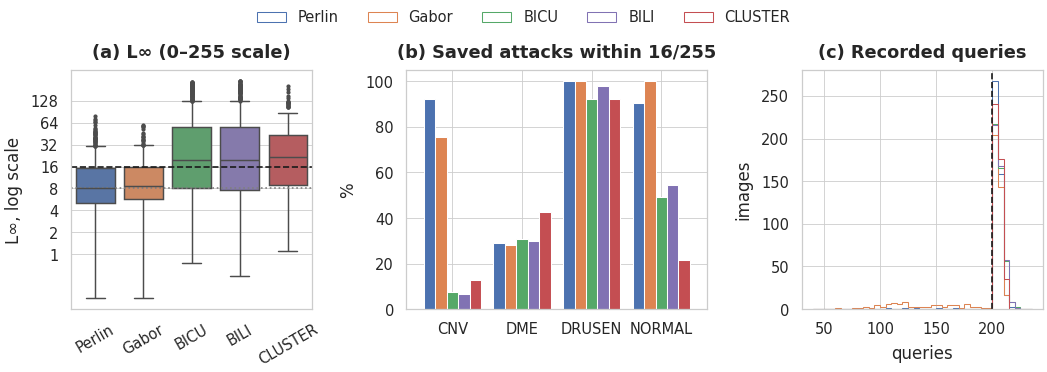

Gabor runs with fewer than 190 recorded queries: 86 of 451; class mix (%) of the two groups:


true,CNV,DME,DRUSEN,NORMAL,n
Gabor runs,,,,,
recorded < 190,9.3,29.1,45.3,16.3,86
recorded >= 190,30.4,26.0,18.4,25.2,365


In [6]:
require(*[f"{g}/{c}-{k}" for g in GENERATORS for c in COHORTS for k in (1, 2, 3, 4, 5, 7, 8)],
        "X1-A", "X1-B", "X2-A", "X2-B", "X3", "X4", "X5")

def build_frame(d, g, coh):
    ok = d.pivot(index="File Name", columns="Processing", values="Correct?").apply(flag_to_bool)
    adv = d[d["Processing"] == "Adversarial"].set_index("File Name"); o = d[d["Processing"] == "Original"].set_index("File Name")
    f = pd.DataFrame({"generator": g, "cohort": coh, "true": o["True Label"], "orig_ok": ok["Original"], "adv_ok": ok["Adversarial"],
                      "linf": adv["Linf"], "l2": adv["L2"], "ssim": adv["SSIM"], "queries": adv["Query Used"]})
    for m in DENOISERS: f[m] = ok[f"{m}-Attack"]
    f["patient"] = [x.split("-")[1] for x in f.index]
    return f

frames = {g: pd.concat([build_frame(rows_ok[g][c], g, c) for c in COHORTS]) for g in GENERATORS}
rows, valid_sets = [], {}
for g in GENERATORS:
    f = frames[g]; elig = f["orig_ok"] == True; flipped = f["adv_ok"] == False      # explicit: missing never counts
    valid_sets[g] = set(f.index[elig & flipped])
    for coh in COHORTS + ["pooled"]:
        s = f if coh == "pooled" else f[f["cohort"] == coh]; e = s["orig_ok"] == True; v = e & (s["adv_ok"] == False)
        rows.append({"Generator": GEN_LABEL[g], "Cohort": coh, "Images": len(s), "Eligible": int(e.sum()),
                     "Excluded (misclassified before attack)": int((~e).sum()), "Successful attacks": int(v.sum()),
                     "Failed or missing": int((e & ~v).sum()), "Success rate (%)": round(v.sum() / max(e.sum(), 1) * 100, 1)})
denoms = pd.DataFrame(rows).set_index(["Generator", "Cohort"])
display(denoms.xs("pooled", level="Cohort"))

COMMON = sorted(set.intersection(*valid_sets.values()))
add_check("V1", "the same eligible images were flipped under every generator", all(s == valid_sets["perlin"] for s in valid_sets.values()),
          f"common valid images: {len(COMMON)}", "paired analyses", "FLAG")
R = {g: frames[g].loc[COMMON].copy() for g in GENERATORS}
for g in GENERATORS:
    R[g]["linf255"] = R[g]["linf"] * 255
    if R[g][DENOISERS].isna().any().any(): raise RuntimeError(f"{g}: missing denoiser outcome on a valid image")
cohort_of = R["perlin"]["cohort"].to_numpy()
n_coh = {c: int((cohort_of == c).sum()) for c in COHORTS}
add_check("E1", "valid attacked images match the counts reported for the study (A 222, B 229)", n_coh == EXPECTED_VALID,
          f"A {n_coh['A']}, B {n_coh['B']}", "reporting", "FLAG")
print(f"paired analysis set: {len(COMMON)} images (A {n_coh['A']}, B {n_coh['B']}), one per patient, identical for all five generators")

rows = []
for g in GENERATORS:
    v = R[g]
    rows.append({"Generator": GEN_LABEL[g], "Search params": GEN_DIM[g], "Linf median (0-255)": v["linf255"].median(),
                 "Linf IQR (0-255)": f"{v['linf255'].quantile(.25):.1f}-{v['linf255'].quantile(.75):.1f}",
                 "Within 8/255 (%)": (v["linf"] <= T8).mean() * 100, "Within 16/255 (%)": (v["linf"] <= T16).mean() * 100,
                 "L2 median ([0,1] scale)": v["l2"].median(), "SSIM median": v["ssim"].median(),
                 "Recorded queries, median": v["queries"].median(), "Recorded > 200 (%)": (v["queries"] > NOMINAL_BUDGET).mean() * 100,
                 f"Recorded < {LOW_Q} (%)": (v["queries"] < LOW_Q).mean() * 100})
t2 = pd.DataFrame(rows).set_index("Generator"); display(t2.round(2))
t2_tex = pd.DataFrame({"Params": t2["Search params"],
                       "Linf median [IQR]": [f"{a:.1f} [{b}]" for a, b in zip(t2["Linf median (0-255)"], t2["Linf IQR (0-255)"])],
                       "<= 8/255 (%)": t2["Within 8/255 (%)"].round(1), "<= 16/255 (%)": t2["Within 16/255 (%)"].round(1),
                       "SSIM": t2["SSIM median"].map(lambda x: f"{x:.2f}"), "Queries": t2["Recorded queries, median"].map(lambda x: f"{x:.0f}"),
                       f"< {LOW_Q} queries (%)": t2[f"Recorded < {LOW_Q} (%)"].round(1)}, index=t2.index)
export_table(t2, "table2_attack_characteristics", f"Saved attack outputs by generator (n = {len(COMMON)} images each; Linf on the 0-255 scale; medians).",
             latex_df=t2_tex, wide=True)

long = pd.concat([R[g].assign(gen=g) for g in GENERATORS], ignore_index=True)
fig, ax = plt.subplots(1, 3, figsize=(FULL_W, 2.4), gridspec_kw={"width_ratios": [1, 1.25, 1]})
sns.boxplot(data=long, x="gen", y="linf255", hue="gen", order=GENERATORS, palette=GEN_COLOR, legend=False, ax=ax[0], fliersize=1, linewidth=0.7)
ax[0].set_yscale("log"); ax[0].axhline(16, color="k", ls="--", lw=0.8); ax[0].axhline(8, color="gray", ls=":", lw=0.8)
ax[0].yaxis.set_major_locator(FixedLocator([1, 2, 4, 8, 16, 32, 64, 128])); ax[0].yaxis.set_major_formatter(G_FMT); ax[0].yaxis.set_minor_locator(FixedLocator([]))
ax[0].set_xticks(range(len(GENERATORS))); ax[0].set_xticklabels([GEN_LABEL[g] for g in GENERATORS], rotation=30)
ax[0].set(title="(a) L∞ (0–255 scale)", xlabel="", ylabel="L∞, log scale")
share = long.groupby(["gen", "true"])["linf"].apply(lambda s: (s <= T16).mean() * 100).unstack("gen")[GENERATORS].loc[CLASSES]
share.columns = [GEN_LABEL[g] for g in GENERATORS]
share.plot.bar(ax=ax[1], color=[GEN_COLOR[g] for g in GENERATORS], width=.82, legend=False)
ax[1].set(title="(b) Saved attacks within 16/255", xlabel="", ylabel="%", ylim=(0, 105)); ax[1].tick_params(axis="x", rotation=0)
for g in GENERATORS: ax[2].hist(R[g]["queries"], bins=np.arange(40, 236, 5), histtype="step", color=GEN_COLOR[g], lw=1.2, label=GEN_LABEL[g])
ax[2].axvline(NOMINAL_BUDGET, color="k", ls="--", lw=0.8); ax[2].set(title="(c) Recorded queries", xlabel="queries", ylabel="images")
h, l = ax[2].get_legend_handles_labels(); fig.legend(h, l, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.08), frameon=False)
plt.tight_layout()
export_fig(fig, "fig02_attack_characteristics", "Saved attack outputs: (a) L-infinity distribution, (b) share within 16/255 by class, (c) recorded query counts")

low = R["gabor"]["queries"] < LOW_Q
grp = np.where(low, f"recorded < {LOW_Q}", f"recorded >= {LOW_Q}")
mix = pd.crosstab(grp, R["gabor"]["true"], normalize="index").reindex(columns=CLASSES) * 100
mix.index.name = "Gabor runs"; mix["n"] = pd.Series(grp).value_counts()
print(f"Gabor runs with fewer than {LOW_Q} recorded queries: {int(low.sum())} of {len(low)}; class mix (%) of the two groups:"); display(mix.round(1))
mark_done("4")


**Notes.**
- Recorded counts usually exceed 200 slightly because the budget is checked once per optimization step.
- A noticeable share of Gabor runs record fewer than 190 queries (table above), unlike the other generators. In the attack code, every Gabor evaluation resets NumPy's global random generator (`BODBA_237628.py` line 134). GPyOpt stops without a new evaluation when its last two points coincide (GPyOpt 1.2.6, `core/bo.py` lines 141–143), and the attack exits after five such rounds (lines 287–292). This is a plausible cause, but no run log confirms it. The low-count runs differ in class mix, so their recovery cannot be attributed to the shorter search.


## 5. Clean-accuracy cost of denoising

All six denoisers were applied to all 1,000 clean test images. This set is separate from the attack cohorts.
- **Clean-accuracy loss** is the baseline accuracy minus the accuracy after denoising, in **percentage points (pp)**.
- **Relative loss** expresses that loss as a percentage of the baseline accuracy.

Intervals are paired, keeping each image's baseline and denoised predictions together, and resample whole patients because some patients contribute several images.

**Pipeline.** This clean evaluation comes from the earlier pipeline, which stored filter outputs as 8-bit PNG files. The attack results come from the revised pipeline (Section 4). The agreement check at the end of this section measures the difference between the two.


baseline accuracy 93.8% on 1000 images from 635 patients


,Accuracy % [95% CI],Loss pp [95% CI],Relative loss (%),Broken,Corrected
Denoiser,,,,,
Gaussian,"90.2 [88.3, 92.0]","3.6 [1.8, 5.4]",3.8,63,27
Median,"80.2 [77.4, 82.9]","13.6 [11.0, 16.3]",14.5,154,18
Bilateral,"77.3 [74.5, 80.1]","16.5 [13.9, 19.1]",17.6,183,18
Non-Local Means,"80.5 [77.8, 83.1]","13.3 [10.8, 16.0]",14.2,158,25
Morphological Opening,"90.7 [88.7, 92.6]","3.1 [1.1, 5.1]",3.3,61,30
Average,"84.3 [81.8, 86.6]","9.5 [7.2, 11.8]",10.1,122,27


paired clean-accuracy difference, Morphological Opening minus Gaussian: +0.5 pp [-1.3, +2.3] (descriptive)


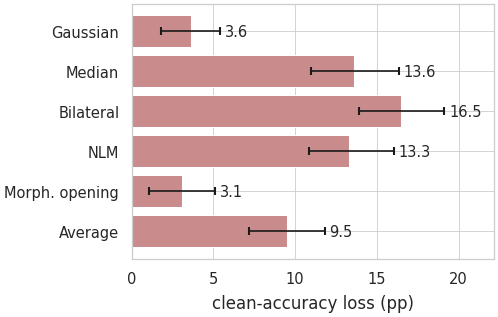

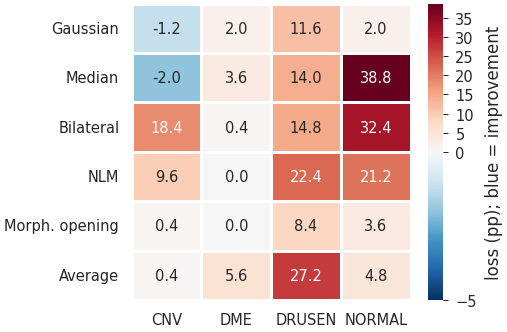

In [7]:
require("C1", "C2", "C3", "C4")
okc = clean.pivot(index="File Name", columns="Processing", values="Correct?").apply(flag_to_bool).astype(float)
c_pat = co.reindex(okc.index)["Patient ID"].astype(str)
base_ok = okc["Original"].to_numpy(); den_ok = okc[[f"{m}-Clean" for m in DENOISERS]].to_numpy()
acc_d = cluster_boot(den_ok, c_pat); loss_d = cluster_boot(base_ok[:, None] - den_ok, c_pat)
base = base_ok.mean() * 100; n_clean = len(okc)
rows = []
for j, m in enumerate(DENOISERS):
    a, l = den_ok[:, j].mean() * 100, (base_ok - den_ok[:, j]).mean() * 100
    (alo, ahi), (llo, lhi) = pct_ci(acc_d[:, j] * 100), pct_ci(loss_d[:, j] * 100)
    o, f_ = base_ok.astype(bool), den_ok[:, j].astype(bool)
    rows.append({"Denoiser": m, "Accuracy % [95% CI]": fmt_ci(a, alo, ahi), "Loss pp [95% CI]": fmt_ci(l, llo, lhi),
                 "Relative loss (%)": round(l / base * 100, 1), "Broken": int((o & ~f_).sum()), "Corrected": int((~o & f_).sum()),
                 "_loss": l, "_lo": llo, "_hi": lhi})
clean_tab = pd.DataFrame(rows).set_index("Denoiser"); clean_loss = clean_tab["_loss"]
t3 = clean_tab[["Accuracy % [95% CI]", "Loss pp [95% CI]", "Relative loss (%)", "Broken", "Corrected"]]
print(f"baseline accuracy {base:.1f}% on {len(okc)} images from {c_pat.nunique()} patients"); display(t3)
t3_tex = t3.rename(columns={"Accuracy % [95% CI]": "Accuracy (%)", "Loss pp [95% CI]": "Loss (pp)", "Relative loss (%)": "Rel. loss (%)", "Corrected": "Fixed"})
t3_tex.index = [DEN_LABEL[m] for m in t3.index]; t3_tex.index.name = "Denoiser"
export_table(t3, "table3_clean_accuracy_loss", f"Clean accuracy and loss after denoising, 1,000 test images (baseline {base:.1f}%; paired, patient-clustered 95% CIs; earlier PNG-based evaluation).",
             latex_df=t3_tex, wide=True)

# direct paired comparison of the two lowest-cost denoisers
two = clean_loss.nsmallest(2).index.tolist()
dd = den_ok[:, DENOISERS.index(two[0])] - den_ok[:, DENOISERS.index(two[1])]
dlo, dhi = pct_ci(cluster_boot(dd[:, None], c_pat)[:, 0] * 100)
print(f"paired clean-accuracy difference, {two[0]} minus {two[1]}: {dd.mean()*100:+.1f} pp [{dlo:+.1f}, {dhi:+.1f}] (descriptive)")

fig, ax = plt.subplots(figsize=(COL_W, 2.3))
y = np.arange(len(DENOISERS)); v = clean_loss.loc[DENOISERS].to_numpy()
ax.barh(y, v, xerr=[v - clean_tab.loc[DENOISERS, "_lo"], clean_tab.loc[DENOISERS, "_hi"] - v], color="#C98B8B", capsize=2, error_kw={"lw": 0.8})
ax.set_yticks(y); ax.set_yticklabels([DEN_LABEL[m] for m in DENOISERS]); ax.invert_yaxis()
for i, (val, hi_) in enumerate(zip(v, clean_tab.loc[DENOISERS, "_hi"])): ax.text(hi_ + 0.3, i, f"{val:.1f}", va="center", fontsize=7)
ax.set(xlabel="clean-accuracy loss (pp)", xlim=(0, clean_tab["_hi"].max() + 3))
plt.tight_layout()
export_fig(fig, "fig03_clean_accuracy_loss", "Clean-accuracy loss per denoiser (pp), 1,000 test images, paired patient-clustered 95% CIs")

true_c = co.reindex(okc.index)["True Label"]
acc_cls = pd.DataFrame({k: okc[k].groupby(true_c.values).mean() * 100 for k in okc.columns}).T.reindex(columns=CLASSES)
drop_cls = acc_cls.loc["Original"] - acc_cls.loc[[f"{m}-Clean" for m in DENOISERS]]; drop_cls.index = [DEN_LABEL[m] for m in DENOISERS]
fig, ax = plt.subplots(figsize=(COL_W, 2.4))
norm = TwoSlopeNorm(vmin=min(-5.0, float(drop_cls.values.min())), vcenter=0.0, vmax=max(5.0, float(drop_cls.values.max())))
sns.heatmap(drop_cls, annot=True, fmt=".1f", cmap="RdBu_r", norm=norm, ax=ax, linewidths=.5, annot_kws={"size": 7},
            cbar_kws={"label": "loss (pp); blue = improvement"})
ax.set(xlabel="", ylabel="")
plt.tight_layout()
export_fig(fig, "fig04_clean_loss_by_class", "Class-specific clean-accuracy loss (pp); negative values (blue) are improvements")


### Agreement between the earlier and revised pipelines on clean images

The 480 cohort images were evaluated by both pipelines: in the 1,000-image clean evaluation (earlier pipeline) and as the clean-denoised rows of the attack runs (revised pipeline; identical in all five generator files, check C5). A clean test image is already exactly 8-bit, so the pipelines can differ only through rounding of the filter output. Filters whose output stays on the 8-bit grid (median, morphological opening and, in OpenCV, non-local means) should agree exactly; filters with fractional outputs (Gaussian, bilateral, average) can differ for images near a decision boundary. Intervals are paired and resample patients within each cohort.


In [8]:
require("C1", "C2", "C3", "C4", "C5")
cl_new = pd.concat([rows_ok["perlin"][c].assign(cohort=c) for c in COHORTS])
ok_new = cl_new.pivot(index="File Name", columns="Processing", values="Correct?").apply(flag_to_bool).astype(float)
pr_new = cl_new.pivot(index="File Name", columns="Processing", values="Prediction")
pr_old = clean.pivot(index="File Name", columns="Processing", values="Prediction").reindex(ok_new.index)
ok_old = okc.reindex(ok_new.index)
b_coh = cl_new[cl_new["Processing"] == "Original"].set_index("File Name").reindex(ok_new.index)["cohort"].to_numpy()
D = np.column_stack([ok_old[f"{m}-Clean"].to_numpy() - ok_new[f"{m}-Clean"].to_numpy() for m in DENOISERS])
bb = strat_boot(D, b_coh, seed=SEED + 7)["pooled"]
rows = []
for j, m in enumerate(DENOISERS):
    lo, hi = pct_ci(bb[:, j]) * 100
    rows.append({"Denoiser": m, "Same prediction (%)": (pr_old[f"{m}-Clean"] == pr_new[f"{m}-Clean"]).mean() * 100,
                 "Correctness changed (n)": int((ok_old[f"{m}-Clean"] != ok_new[f"{m}-Clean"]).sum()),
                 "Earlier pipeline acc. (%)": ok_old[f"{m}-Clean"].mean() * 100, "Revised pipeline acc. (%)": ok_new[f"{m}-Clean"].mean() * 100,
                 "Earlier minus revised (pp) [95% CI]": fmt_ci(D[:, j].mean() * 100, lo, hi)})
bridge = pd.DataFrame(rows).set_index("Denoiser")
orig_same = (pr_old["Original"] == pr_new["Original"]).mean() * 100
print(f"{len(ok_new)} cohort images evaluated by both pipelines; original (undenoised) predictions identical: {orig_same:.1f}%")
display(bridge.round(1))
bridge_max = float(np.abs(D.mean(axis=0)).max() * 100); bridge_arg = DENOISERS[int(np.argmax(np.abs(D.mean(axis=0))))]
bridge_exact = [m for j, m in enumerate(DENOISERS) if (D[:, j] == 0).all()]
print(f"largest accuracy difference between pipelines: {bridge_max:.1f} pp ({bridge_arg}); identical predictions for: {', '.join(bridge_exact) or 'none'}")
bt = bridge.rename(columns={"Same prediction (%)": "Same pred. (%)", "Correctness changed (n)": "Changed (n)", "Earlier pipeline acc. (%)": "Earlier (%)",
                            "Revised pipeline acc. (%)": "Revised (%)", "Earlier minus revised (pp) [95% CI]": "Diff. (pp)"})
bt.index = [DEN_LABEL[m] for m in bridge.index]; bt.index.name = "Denoiser"
export_table(bridge, "table3b_clean_pipeline_agreement", f"Clean accuracy on the {len(ok_new)} cohort images under the earlier (PNG) and revised (float) pipelines.",
             latex_df=bt, wide=True)
mark_done("5")


480 cohort images evaluated by both pipelines; original (undenoised) predictions identical: 100.0%


,Same prediction (%),Correctness changed (n),Earlier pipeline acc. (%),Revised pipeline acc. (%),Earlier minus revised (pp) [95% CI]
Denoiser,,,,,
Gaussian,98.3,7,88.5,88.3,"0.2 [-0.8, 1.2]"
Median,100.0,0,80.6,80.6,"0.0 [0.0, 0.0]"
Bilateral,98.5,6,77.5,78.3,"-0.8 [-1.9, 0.0]"
Non-Local Means,100.0,0,82.3,82.3,"0.0 [0.0, 0.0]"
Morphological Opening,100.0,0,89.6,89.6,"0.0 [0.0, 0.0]"
Average,98.1,7,82.7,83.3,"-0.6 [-1.7, 0.4]"


largest accuracy difference between pipelines: 0.8 pp (Bilateral); identical predictions for: Median, Non-Local Means, Morphological Opening


## 6. Recovery across perturbation generators

**Recovery rate:** the share of valid attacked images whose denoised adversarial output is classified as the true class.

**Sample.** The same 451 eligible, successfully attacked images (cohort A 222, cohort B 229, one per patient) are used for every generator and denoiser. These are repeated measurements on the same images, not 451 new patients per condition. Attack results pool cohorts A and B unless stated otherwise. Clean-image results (Section 5) use the 1,000-image test set from the earlier evaluation; their agreement with the revised pipeline is checked there.

**Intervals** come from the paired patient bootstrap, resampled within cohort with the original cohort weights kept when pooling. The highest recovery per generator is marked as an observed result. It does not imply that denoiser is generally superior.


Recovery % [95% CI], n = 451 images per cell:


,Perlin,Gabor,BICU,BILI,CLUSTER
Denoiser,,,,,
Gaussian,"51.4 [46.8, 56.1]","58.1 [53.7, 62.7]","42.8 [38.1, 47.5]","42.8 [38.4, 47.5]","84.0 [80.5, 87.1]"
Median,"54.5 [49.9, 59.0]","43.7 [39.0, 48.3]","46.6 [41.9, 51.2]","44.8 [40.1, 49.4]","67.0 [62.3, 71.4]"
Bilateral,"49.0 [44.3, 53.7]","40.8 [36.1, 45.5]","50.3 [45.7, 55.0]","47.5 [42.8, 51.9]","74.5 [70.5, 78.3]"
Non-Local Means,"57.6 [53.0, 61.9]","48.1 [43.5, 52.8]","51.2 [46.6, 55.7]","50.8 [45.9, 55.4]","58.8 [54.1, 63.4]"
Morphological Opening,"63.9 [59.4, 68.1]","49.0 [44.3, 53.7]","56.1 [51.2, 60.8]","56.3 [51.7, 60.8]","81.8 [78.3, 85.4]"
Average,"54.3 [49.9, 59.0]","54.8 [50.3, 59.2]","47.7 [43.2, 52.3]","49.2 [44.3, 53.9]","75.4 [71.4, 79.2]"


highest observed recovery per generator: {'Perlin': 'Morphological Opening (63.9%)', 'Gabor': 'Gaussian (58.1%)', 'BICU': 'Morphological Opening (56.1%)', 'BILI': 'Morphological Opening (56.3%)', 'CLUSTER': 'Gaussian (84.0%)'}


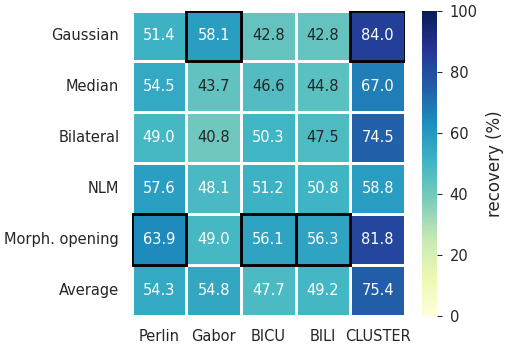

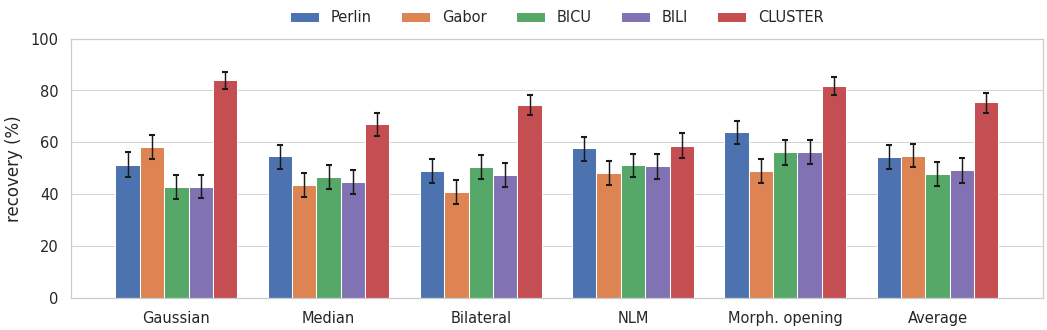

In [9]:
require("V1", "X4")
cols = [(g, m) for g in GENERATORS for m in DENOISERS]
X = np.column_stack([R[g][m].astype(float).to_numpy() for g, m in cols])
BOOT = strat_boot(X, cohort_of)
est = {"pooled": X.mean(axis=0), "A": X[cohort_of == "A"].mean(axis=0), "B": X[cohort_of == "B"].mean(axis=0)}
CI = {k: pct_ci(BOOT[k]) for k in BOOT}
REC = pd.DataFrame({g: {m: est["pooled"][cols.index((g, m))] * 100 for m in DENOISERS} for g in GENERATORS}).loc[DENOISERS]

t4 = pd.DataFrame({GEN_LABEL[g]: {m: fmt_ci(est["pooled"][cols.index((g, m))] * 100, CI["pooled"][0, cols.index((g, m))] * 100,
                                         CI["pooled"][1, cols.index((g, m))] * 100) for m in DENOISERS} for g in GENERATORS}).loc[DENOISERS]
t4.index.name = "Denoiser"
print(f"Recovery % [95% CI], n = {len(COMMON)} images per cell:"); display(t4)
t4_tex = t4.copy(); t4_tex.index = [DEN_LABEL[m] for m in t4.index]; t4_tex.index.name = "Denoiser"
export_table(t4, "table4_recovery_pooled", f"Recovery (%) by denoiser and generator, pooled cohorts (n = {len(COMMON)} per cell; 95% bootstrap CIs).",
             latex_df=t4_tex, wide=True)
print("highest observed recovery per generator:", {GEN_LABEL[g]: f"{REC[g].idxmax()} ({REC[g].max():.1f}%)" for g in GENERATORS})

fig, ax = plt.subplots(figsize=(COL_W, 2.5))
hm = REC.copy(); hm.index = [DEN_LABEL[m] for m in DENOISERS]; hm.columns = [GEN_LABEL[g] for g in GENERATORS]
sns.heatmap(hm, annot=True, fmt=".1f", cmap="YlGnBu", vmin=0, vmax=100, ax=ax, linewidths=.5, annot_kws={"size": 7}, cbar_kws={"label": "recovery (%)"})
for j, g in enumerate(GENERATORS):
    ax.add_patch(Rectangle((j, DENOISERS.index(REC[g].idxmax())), 1, 1, fill=False, edgecolor="black", lw=1.4))
ax.set(xlabel="", ylabel="")
plt.tight_layout()
export_fig(fig, "fig05_recovery_heatmap", "Recovery (%) by denoiser and generator; outlined cell = highest observed recovery per generator")

fig, ax = plt.subplots(figsize=(FULL_W, 2.4)); w = 0.8 / len(GENERATORS); x = np.arange(len(DENOISERS))
for i, g in enumerate(GENERATORS):
    j = [cols.index((g, m)) for m in DENOISERS]; v = est["pooled"][j] * 100
    ax.bar(x + (i - (len(GENERATORS) - 1) / 2) * w, v, w, yerr=[v - CI["pooled"][0, j] * 100, CI["pooled"][1, j] * 100 - v],
           capsize=1.5, color=GEN_COLOR[g], label=GEN_LABEL[g], error_kw={"lw": 0.7})
ax.set_xticks(x); ax.set_xticklabels([DEN_LABEL[m] for m in DENOISERS]); ax.grid(axis="x", visible=False)
ax.set(ylabel="recovery (%)", ylim=(0, 100)); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.16), frameon=False)
plt.tight_layout()
export_fig(fig, "fig06_recovery_bars_ci", "Recovery (%) by denoiser and generator with 95% bootstrap CIs")


**Does recovery differ across the five generators?** Cochran's Q for each denoiser compares the five paired recovery outcomes. Holm correction is applied across the six denoiser-specific tests.


In [10]:
q_rows = []
for m in DENOISERS:
    q = cochrans_q(np.column_stack([R[g][m].astype(int) for g in GENERATORS]))
    q_rows.append({"Denoiser": m, "Q": q.statistic, "df": len(GENERATORS) - 1, "raw p": q.pvalue})
t5 = pd.DataFrame(q_rows).set_index("Denoiser"); t5["Holm p"] = multipletests(t5["raw p"], method="holm")[1]
display(t5.assign(**{"raw p": t5["raw p"].map(fmt_p), "Holm p": t5["Holm p"].map(fmt_p)}).round(1))
t5_tex = t5.copy(); t5_tex.index = [DEN_LABEL[m] for m in t5.index]; t5_tex.index.name = "Denoiser"
export_table(t5, "table5_cochran_q", "Cochran's Q across the five generators for each denoiser (Holm correction across six tests).", p_cols=("raw p", "Holm p"),
             latex_df=t5_tex, wide=False)
mark_done("6")


,Q,df,raw p,Holm p
Denoiser,,,,
Gaussian,261.0,4,2.8e-55,1.7e-54
Median,93.0,4,3.0e-19,6.0e-19
Bilateral,186.9,4,2.5e-39,1.2e-38
Non-Local Means,21.1,4,3.0e-04,3.0e-04
Morphological Opening,145.9,4,1.5e-30,6.1e-30
Average,120.9,4,3.4e-25,1.0e-24


## 7. Pairwise generator comparisons

For each of three selected denoisers (Morphological Opening, Non-Local Means and Gaussian), exact paired McNemar tests compare recovery between every pair of generators on the same 451 images. That gives 10 pairs per denoiser and **30 tests**, with Holm correction across all 30.

These tests compare generators *within* a denoiser. They do not compare denoisers with each other; Section 11 estimates differences between denoisers directly.
- The **difference** is recovery under the first generator minus the second, in percentage points.
- The **discordant counts** are images recovered under only one of the two generators.

Each exact McNemar p-value is checked against a two-sided exact binomial test on the discordant pairs.


In [11]:
rows, verified = [], 0
for m in SELECTED:
    for g1, g2 in combinations(GENERATORS, 2):
        a, b = R[g1][m].astype(bool).to_numpy(), R[g2][m].astype(bool).to_numpy()
        n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
        p = mcnemar(np.array([[np.sum(~a & ~b), n01], [n10, np.sum(a & b)]]), exact=True).pvalue
        p_chk = stats.binomtest(n10, n10 + n01, 0.5).pvalue if (n10 + n01) else 1.0
        if abs(p - p_chk) > 1e-9: raise RuntimeError(f"McNemar verification failed for {m}, {g1} vs {g2}")
        verified += 1
        rows.append({"Denoiser": m, "Comparison": f"{GEN_LABEL[g1]} vs {GEN_LABEL[g2]}", "n": len(a),
                     "Recovery 1st (%)": a.mean() * 100, "Recovery 2nd (%)": b.mean() * 100, "Difference (pp)": (a.mean() - b.mean()) * 100,
                     "Only 1st": n10, "Only 2nd": n01, "raw p": p})
t6 = pd.DataFrame(rows); t6["Holm p"] = multipletests(t6["raw p"], method="holm")[1]
t6 = t6.set_index(["Denoiser", "Comparison"])
with pd.option_context("display.max_rows", 40):
    display(t6.assign(**{"raw p": t6["raw p"].map(fmt_p), "Holm p": t6["Holm p"].map(fmt_p)}).round(1))
print(f"{verified} of 30 exact McNemar p-values verified against exact binomial tests")
print("Holm-adjusted p < 0.05:", {m: f"{int((t6.loc[m, 'Holm p'] < 0.05).sum())} of 10" for m in SELECTED}, f"| total {int((t6['Holm p'] < 0.05).sum())} of 30")
t6r = t6.reset_index()
t6_tex = pd.DataFrame({"Comparison": t6r["Comparison"],
                       "Recovery (%)": [f"{a:.1f} / {b:.1f}" for a, b in zip(t6r["Recovery 1st (%)"], t6r["Recovery 2nd (%)"])],
                       "Diff. (pp)": t6r["Difference (pp)"].round(1), "Only 1st": t6r["Only 1st"], "Only 2nd": t6r["Only 2nd"],
                       "raw p": t6r["raw p"], "Holm p": t6r["Holm p"]}, index=t6r["Denoiser"].map(DEN_LABEL).rename("Denoiser"))
export_table(t6r.set_index("Denoiser"), "table6_mcnemar_30",
             f"Exact McNemar comparisons between generators within each selected denoiser (n = {len(COMMON)} per test; Holm correction across 30 tests).",
             p_cols=("raw p", "Holm p"), latex_df=t6_tex, wide=True)
mark_done("7")


n  Recovery 1st (%)  \
Denoiser              Comparison                                 
Morphological Opening Perlin vs Gabor    451              63.9   
                      Perlin vs BICU     451              63.9   
                      Perlin vs BILI     451              63.9   
                      Perlin vs CLUSTER  451              63.9   
                      Gabor vs BICU      451              49.0   
                      Gabor vs BILI      451              49.0   
                      Gabor vs CLUSTER   451              49.0   
                      BICU vs BILI       451              56.1   
                      BICU vs CLUSTER    451              56.1   
                      BILI vs CLUSTER    451              56.3   
Non-Local Means       Perlin vs Gabor    451              57.6   
                      Perlin vs BICU     451              57.6   
                      Perlin vs BILI     451              57.6   
                      Perlin vs CLUSTER  451              57.6   
                      Gabor vs BICU      451              48.1   
                      Gabor vs BILI      451              48.1   
                      Gabor vs CLUSTER   451              48.1   
                      BICU vs BILI       451              51.2   
                      BICU vs CLUSTER    451              51.2   
                      BILI vs CLUSTER    451              50.8   
Gaussian              Perlin vs Gabor    451              51.4   
                      Perlin vs BICU     451              51.4   
                      Perlin vs BILI     451              51.4   
                      Perlin vs CLUSTER  451              51.4   
                      Gabor vs BICU      451              58.1   
                      Gabor vs BILI      451              58.1   
                      Gabor vs CLUSTER   451              58.1   
                      BICU vs BILI       451              42.8   
                      BICU vs CLUSTER    451              42.8   
                      BILI vs CLUSTER    451              42.8   

                                         Recovery 2nd (%)  Difference (pp)  \
Denoiser              Comparison                                             
Morphological Opening Perlin vs Gabor                49.0             14.9   
                      Perlin vs BICU                 56.1              7.8   
                      Perlin vs BILI                 56.3              7.5   
                      Perlin vs CLUSTER              81.8            -18.0   
                      Gabor vs BICU                  56.1             -7.1   
                      Gabor vs BILI                  56.3             -7.3   
                      Gabor vs CLUSTER               81.8            -32.8   
                      BICU vs BILI                   56.3             -0.2   
                      BICU vs CLUSTER                81.8            -25.7   
                      BILI vs CLUSTER                81.8            -25.5   
Non-Local Means       Perlin vs Gabor                48.1              9.5   
                      Perlin vs BICU                 51.2              6.4   
                      Perlin vs BILI                 50.8              6.9   
                      Perlin vs CLUSTER              58.8             -1.1   
                      Gabor vs BICU                  51.2             -3.1   
                      Gabor vs BILI                  50.8             -2.7   
                      Gabor vs CLUSTER               58.8            -10.6   
                      BICU vs BILI                   50.8              0.4   
                      BICU vs CLUSTER                58.8             -7.5   
                      BILI vs CLUSTER                58.8             -8.0   
Gaussian              Perlin vs Gabor                58.1             -6.7   
                      Perlin vs BICU                 42.8              8.6   
                      Perlin vs BILI                 42.8 

30 of 30 exact McNemar p-values verified against exact binomial tests
Holm-adjusted p < 0.05: {'Morphological Opening': '5 of 10', 'Non-Local Means': '2 of 10', 'Gaussian': '6 of 10'} | total 13 of 30


## 8. Cohort consistency

Cohorts A and B are disjoint patient sets drawn from the same test set and analysed together. Agreement between them is a **consistency check**, not independent external validation. The figure shows estimates for A, B and the pooled set side by side. The summary describes whether directions and magnitudes agree. Similar estimates do not establish equivalence.


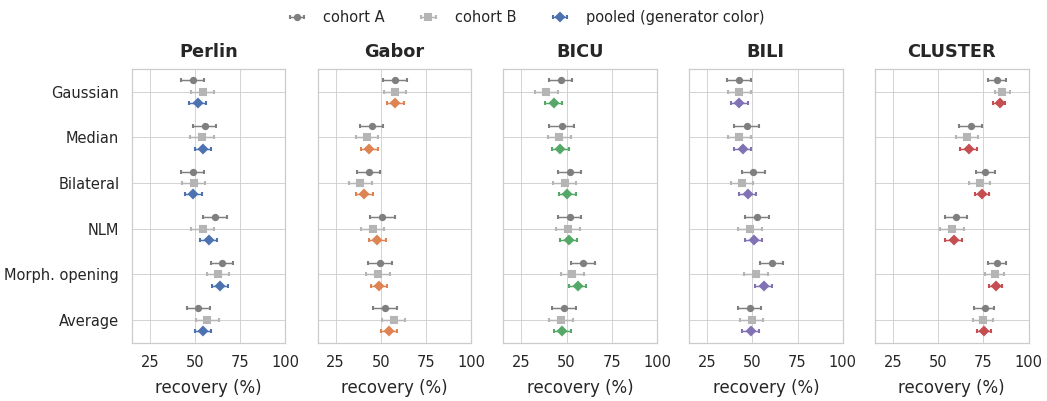

cells where |A - B| <= 5 pp: 23 of 30
largest cohort differences:
  Morph. opening under BILI: A 60.8% vs B 52.0% (+8.8 pp)
  Gaussian under BICU: A 46.8% vs B 38.9% (+8.0 pp)
  NLM under Perlin: A 61.3% vs B 54.1% (+7.1 pp)
highest observed denoiser per generator, same in both cohorts for: ['Perlin', 'Gabor', 'BICU', 'BILI', 'CLUSTER'] | different for: {}


In [12]:
fig, axs = plt.subplots(1, len(GENERATORS), figsize=(FULL_W, 2.6), sharey=True)
for ax, g in zip(axs, GENERATORS):
    for k, (dy, col, mk) in {"A": (-0.25, "#7F7F7F", "o"), "B": (0.0, "#B5B5B5", "s"), "pooled": (0.25, GEN_COLOR[g], "D")}.items():
        j = [cols.index((g, m)) for m in DENOISERS]; v = est[k][j] * 100; yy = np.arange(len(DENOISERS)) + dy
        ax.errorbar(v, yy, xerr=[v - CI[k][0, j] * 100, CI[k][1, j] * 100 - v], fmt=mk, color=col, capsize=1, ms=2.5, lw=0.7,
                    label=("pooled (generator color)" if k == "pooled" else f"cohort {k}") if g == GENERATORS[0] else None)
    ax.set_yticks(range(len(DENOISERS))); ax.set_yticklabels([DEN_LABEL[m] for m in DENOISERS]); ax.set_ylim(len(DENOISERS) - 0.5, -0.5)
    ax.set(title=GEN_LABEL[g], xlim=(15, 100), xlabel="recovery (%)"); ax.set_xticks([25, 50, 75, 100])
fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.07), frameon=False)
plt.tight_layout()
export_fig(fig, "fig07_cohort_consistency", "Recovery (%) with 95% CIs for cohort A, cohort B and pooled, by generator and denoiser")

dAB = (est["A"] - est["B"]) * 100
topA = {g: max(DENOISERS, key=lambda m: est["A"][cols.index((g, m))]) for g in GENERATORS}
topB = {g: max(DENOISERS, key=lambda m: est["B"][cols.index((g, m))]) for g in GENERATORS}
print(f"cells where |A - B| <= 5 pp: {int((np.abs(dAB) <= 5).sum())} of {len(cols)}")
print("largest cohort differences:")
for i in np.argsort(-np.abs(dAB))[:3]:
    g, m = cols[i]; print(f"  {DEN_LABEL[m]} under {GEN_LABEL[g]}: A {est['A'][i]*100:.1f}% vs B {est['B'][i]*100:.1f}% ({dAB[i]:+.1f} pp)")
print("highest observed denoiser per generator, same in both cohorts for:", [GEN_LABEL[g] for g in GENERATORS if topA[g] == topB[g]],
      "| different for:", {GEN_LABEL[g]: (DEN_LABEL[topA[g]], DEN_LABEL[topB[g]]) for g in GENERATORS if topA[g] != topB[g]})
mark_done("8")


## 9. Class-specific recovery (descriptive)

Recovery by true class for every generator and denoiser, on one shared 0–100% scale. Class counts appear in the note below the figure. These results are descriptive and are not tested.


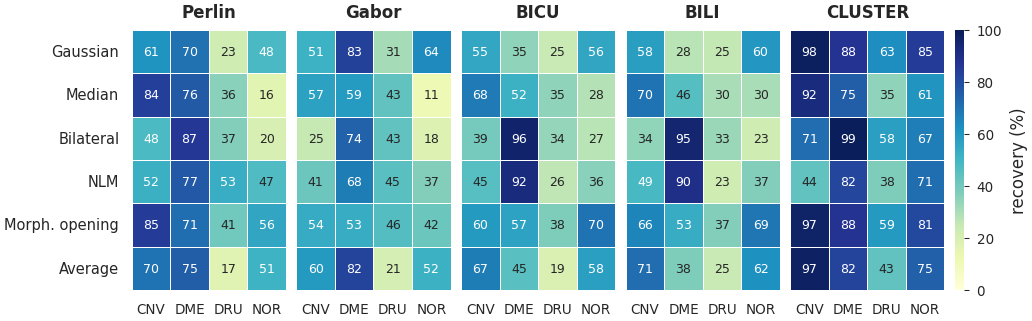

class denominators (valid attacked images, same for every generator): {'CNV': 119, 'DME': 120, 'DRUSEN': 106, 'NORMAL': 106} | DRU = DRUSEN, NOR = NORMAL
lowest-recovery class per denoiser (mean over generators): {'Gaussian': 'DRUSEN (33%)', 'Median': 'NORMAL (29%)', 'Bilateral': 'NORMAL (31%)', 'NLM': 'DRUSEN (37%)', 'Morph. opening': 'DRUSEN (44%)', 'Average': 'DRUSEN (25%)'}


In [13]:
n_cls = R["perlin"]["true"].value_counts().reindex(CLASSES)
fig = plt.figure(figsize=(FULL_W, 2.25))
gs = fig.add_gridspec(1, len(GENERATORS) + 1, width_ratios=[1] * len(GENERATORS) + [0.06], wspace=0.08)
cax = fig.add_subplot(gs[0, -1])
for i, g in enumerate(GENERATORS):
    a = fig.add_subplot(gs[0, i])
    tab = pd.DataFrame({c: R[g][R[g]["true"] == c][DENOISERS].astype(float).mean() * 100 for c in CLASSES}).loc[DENOISERS]
    tab.index = [DEN_LABEL[m] for m in DENOISERS]; tab.columns = ["CNV", "DME", "DRU", "NOR"]
    sns.heatmap(tab, annot=True, fmt=".0f", cmap="YlGnBu", vmin=0, vmax=100, ax=a, cbar=(i == 0), cbar_ax=cax if i == 0 else None,
                linewidths=.4, annot_kws={"size": 6}, cbar_kws={"label": "recovery (%)"})
    a.set_title(GEN_LABEL[g], fontsize=8); a.set_xlabel(""); a.set_ylabel(""); a.tick_params(axis="x", labelsize=6.5, rotation=0)
    if i: a.set_yticklabels([]); a.tick_params(axis="y", length=0)
    else: a.tick_params(axis="y", labelsize=7)
cax.tick_params(labelsize=6.5)
export_fig(fig, "fig08_class_recovery_heatmap",
           "Recovery (%) by true class, generator and denoiser; shared 0-100% scale; DRU = DRUSEN, NOR = NORMAL; n per class: " +
           ", ".join(f"{c} {int(n_cls[c])}" for c in CLASSES))
print("class denominators (valid attacked images, same for every generator):", {c: int(n_cls[c]) for c in CLASSES}, "| DRU = DRUSEN, NOR = NORMAL")
by_cls = {m: {c: np.mean([R[g].loc[R[g]["true"] == c, m].astype(float).mean() for g in GENERATORS]) * 100 for c in CLASSES} for m in DENOISERS}
low_cls = {m: min(by_cls[m], key=by_cls[m].get) for m in DENOISERS}
print("lowest-recovery class per denoiser (mean over generators):", {DEN_LABEL[m]: f"{c} ({by_cls[m][c]:.0f}%)" for m, c in low_cls.items()})
mark_done("9")


## 10. Recovery–clean-accuracy trade-offs

Two summaries across generators:
- **Equal-weight mean across the five tested generators.** Each configuration counts equally, so the value depends on which configurations are included and how they are weighted. Supporting analysis 11d shows the same summary for the first three generators.
- **Minimum observed aggregate recovery across the tested generators.** The lowest of the five pooled recovery rates for a denoiser.

Neither is typical real-world recovery, adaptive robustness, a per-image worst case, or performance across all attack families.

The table also compares the highest-mean denoiser with each alternative. That denoiser was selected *because* it had the highest observed mean, and the five intervals are ordinary, unadjusted 95% CIs. These comparisons are **exploratory and descriptive**, not a multiplicity-controlled test that it beats every alternative.


,Equal-weight mean (%),95% CI,Minimum observed (%),At generator,Maximum observed (%),Clean loss (pp)
Gaussian,55.8,"[53.1, 58.6]",42.8,BICU,84.0,3.6
Median,51.3,"[48.3, 54.4]",43.7,Gabor,67.0,13.6
Bilateral,52.4,"[49.4, 55.6]",40.8,Gabor,74.5,16.5
Non-Local Means,53.3,"[50.3, 56.1]",48.1,Gabor,58.8,13.3
Morphological Opening,61.4,"[58.8, 64.0]",49.0,Gabor,81.8,3.1
Average,56.3,"[53.3, 59.2]",47.7,BICU,75.4,9.5


,Difference pp [unadjusted 95% CI]
Comparison (exploratory),
Morphological Opening minus Gaussian,"5.6 [2.7, 8.4]"
Morphological Opening minus Median,"10.1 [6.9, 13.2]"
Morphological Opening minus Bilateral,"9.0 [5.1, 12.8]"
Morphological Opening minus Non-Local Means,"8.1 [4.4, 11.9]"
Morphological Opening minus Average,"5.1 [2.2, 8.0]"


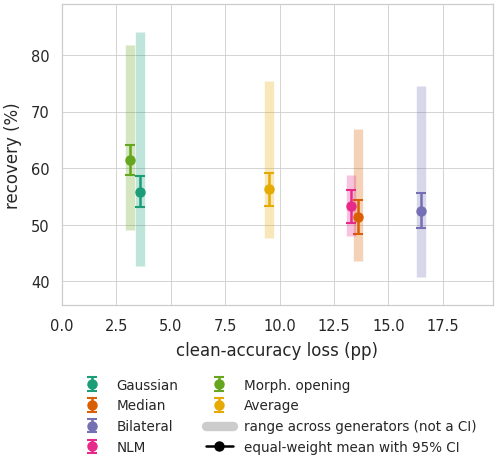

In [14]:
def gen_summary(gens, seed):
    eq = {m: np.mean([R[g][m].astype(float).to_numpy() for g in gens], axis=0) for m in DENOISERS}   # per patient, equal weight
    Xe = np.column_stack([eq[m] for m in DENOISERS]); ci_ = pct_ci(strat_boot(Xe, cohort_of, seed=seed)["pooled"]).T * 100
    s = pd.DataFrame({"Equal-weight mean (%)": Xe.mean(axis=0) * 100, "95% CI": [f"[{lo:.1f}, {hi:.1f}]" for lo, hi in ci_],
                      "Minimum observed (%)": REC[gens].min(axis=1).to_numpy(), "At generator": [GEN_LABEL[g] for g in REC[gens].idxmin(axis=1)],
                      "Maximum observed (%)": REC[gens].max(axis=1).to_numpy(), "Clean loss (pp)": clean_loss.reindex(DENOISERS).to_numpy()}, index=DENOISERS)
    b = s["Equal-weight mean (%)"].idxmax(); rows_ = []
    for m in DENOISERS:
        if m == b: continue
        d = eq[b] - eq[m]; lo, hi = pct_ci(strat_boot(d[:, None], cohort_of, seed=seed + 1)["pooled"][:, 0]) * 100
        rows_.append({"Comparison (exploratory)": f"{b} minus {m}", "Difference pp [unadjusted 95% CI]": fmt_ci(d.mean() * 100, lo, hi)})
    return s, b, pd.DataFrame(rows_).set_index("Comparison (exploratory)"), dict(zip(DENOISERS, ci_))

summ, best, diff_tab, mean_ci = gen_summary(GENERATORS, SEED + 4)
display(summ.round(1)); display(diff_tab)

from matplotlib.lines import Line2D
fig, ax = plt.subplots(figsize=(COL_W, 3.4))
for m in DENOISERS:
    x0, y0 = clean_loss[m], summ.loc[m, "Equal-weight mean (%)"]; lo, hi = mean_ci[m]
    ax.vlines(x0, REC.loc[m].min(), REC.loc[m].max(), color=DEN_COLOR[m], alpha=0.28, lw=4.5)
    ax.errorbar(x0, y0, yerr=[[y0 - lo], [hi - y0]], fmt="o", color=DEN_COLOR[m], ms=4, capsize=2.5, lw=1.2, label=DEN_LABEL[m])
key = [Line2D([0], [0], color="gray", alpha=0.4, lw=4.5, label="range across generators (not a CI)"),
       Line2D([0], [0], color="black", marker="o", ms=4, lw=1.2, label="equal-weight mean with 95% CI")]
h, l = ax.get_legend_handles_labels()
ax.legend(h + key, l + [k.get_label() for k in key], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=6.5, frameon=False)
ax.set(xlabel="clean-accuracy loss (pp)", ylabel="recovery (%)", xlim=(0, clean_loss.max() * 1.2), ylim=(REC.values.min() - 5, REC.values.max() + 5))
plt.tight_layout()
export_fig(fig, "fig09_recovery_vs_clean_cost", "Equal-weight mean recovery across five generators (95% CI) and range across generators versus clean-accuracy loss on the 1,000 test images")
mark_done("10")


## 11. Supporting sensitivity analyses

These analyses support the main results and are **exploratory**.


### 11a. Interaction contrasts

Each contrast asks whether a denoiser's advantage over Gaussian differs between Perlin and Gabor, estimated directly in percentage points (positive = larger advantage under Perlin):
- **Contrast A:** (Morphological Opening − Gaussian under Perlin) − (Morphological Opening − Gaussian under Gabor).
- **Contrast B:** (NLM − Gaussian under Perlin) − (NLM − Gaussian under Gabor).

Each patient contributes all four outcomes, and the bootstrap keeps them together. The contrasts are reported with 95% CIs for cohort A, cohort B and pooled. An interaction is not inferred from separate significant and non-significant tests.


,A,B,pooled
"Contrast A: MO vs Gaussian, Perlin minus Gabor","24.8 [15.3, 34.7]","18.3 [8.3, 29.3]","21.5 [14.4, 28.6]"
"Contrast B: NLM vs Gaussian, Perlin minus Gabor","19.8 [7.7, 31.5]","12.7 [1.3, 23.6]","16.2 [7.8, 24.2]"


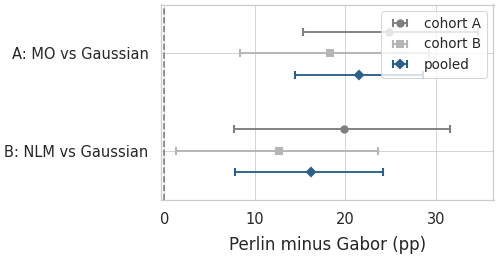

In [15]:
def pp(m, g): return R[g][m].astype(float).to_numpy()
G_, MO, NL = "Gaussian", "Morphological Opening", "Non-Local Means"
comp = {"Contrast A: MO vs Gaussian, Perlin minus Gabor": (pp(MO, "perlin") - pp(G_, "perlin")) - (pp(MO, "gabor") - pp(G_, "gabor")),
        "Contrast B: NLM vs Gaussian, Perlin minus Gabor": (pp(NL, "perlin") - pp(G_, "perlin")) - (pp(NL, "gabor") - pp(G_, "gabor"))}
names = list(comp); Xc = np.column_stack([comp[k] for k in names]); bc = strat_boot(Xc, cohort_of, seed=SEED + 1)
contr = {}
for j, k in enumerate(names):
    contr[k] = {}
    for coh in ["A", "B", "pooled"]:
        pt = (Xc[cohort_of == coh, j].mean() if coh != "pooled" else Xc[:, j].mean()) * 100; lo, hi = pct_ci(bc[coh][:, j]) * 100
        contr[k][coh] = (pt, lo, hi)
display(pd.DataFrame({k: {c: fmt_ci(*v) for c, v in d.items()} for k, d in contr.items()}).T)

fig, ax = plt.subplots(figsize=(COL_W, 1.9))
for i, k in enumerate(names):
    for dy, coh, col, mk in [(-0.22, "A", "#7F7F7F", "o"), (0, "B", "#B5B5B5", "s"), (0.22, "pooled", "#2C5F8A", "D")]:
        pt, lo, hi = contr[k][coh]
        ax.errorbar(pt, i + dy, xerr=[[pt - lo], [hi - pt]], fmt=mk, color=col, capsize=2, ms=3, lw=0.9, label=(coh if coh == "pooled" else f"cohort {coh}") if i == 0 else None)
ax.axvline(0, color="gray", ls="--", lw=0.8); ax.set_yticks([0, 1]); ax.set_yticklabels(["A: MO vs Gaussian", "B: NLM vs Gaussian"]); ax.set_ylim(1.5, -0.5)
ax.set(xlabel="Perlin minus Gabor (pp)"); ax.legend(fontsize=6.5, loc="upper right")
plt.tight_layout()
export_fig(fig, "fig10_interaction_contrasts", "Interaction contrasts: change in advantage over Gaussian, Perlin minus Gabor (pp, 95% CI)")


### 11b. Advantage over Gaussian within each generator

The recovery difference between Morphological Opening or NLM and Gaussian on the same images, under each generator, for cohort A, cohort B and pooled. A sign that changes across generators means the ranking against Gaussian depends on the generator configuration.


A (pp)                B (pp)  \
Denoiser minus Gaussian Generator                                               
Morph. opening          Perlin         16.2 [9.0, 23.4]       8.7 [1.7, 15.7]   
                        Gabor         -8.6 [-17.1, 0.0]    -9.6 [-17.5, -2.2]   
                        BICU           12.2 [5.0, 19.4]      14.4 [6.6, 22.3]   
                        BILI          18.0 [10.4, 25.2]       9.2 [1.7, 16.6]   
                        CLUSTER         0.0 [-6.3, 6.3]     -4.4 [-10.5, 1.3]   
NLM                     Perlin         12.6 [3.6, 21.6]       0.0 [-9.2, 8.7]   
                        Gabor         -7.2 [-16.2, 1.8]   -12.7 [-21.0, -3.9]   
                        BICU           5.0 [-3.6, 13.1]      11.8 [3.1, 21.4]   
                        BILI            9.9 [0.0, 18.9]      6.1 [-2.6, 15.7]   
                        CLUSTER    -22.5 [-30.6, -14.9]  -27.9 [-34.9, -20.5]   

                                            pooled (pp)  Same sign in A and B  
Denoiser minus Gaussian Generator                                              
Morph. opening          Perlin         12.4 [7.5, 17.5]                  True  
                        Gabor        -9.1 [-14.6, -3.5]                  True  
                        BICU           13.3 [8.0, 18.8]                  True  
                        BILI           13.5 [8.0, 18.8]                  True  
                        CLUSTER        -2.2 [-6.4, 2.0]                 False  
NLM                     Perlin         6.2 [-0.2, 12.4]                 False  
                        Gabor       -10.0 [-16.2, -3.8]                  True  
                        BICU            8.4 [2.2, 14.6]                  True  
                        BILI            8.0 [1.1, 14.4]                  True  
                        CLUSTER    -25.3 [-30.6, -19.7]                  True

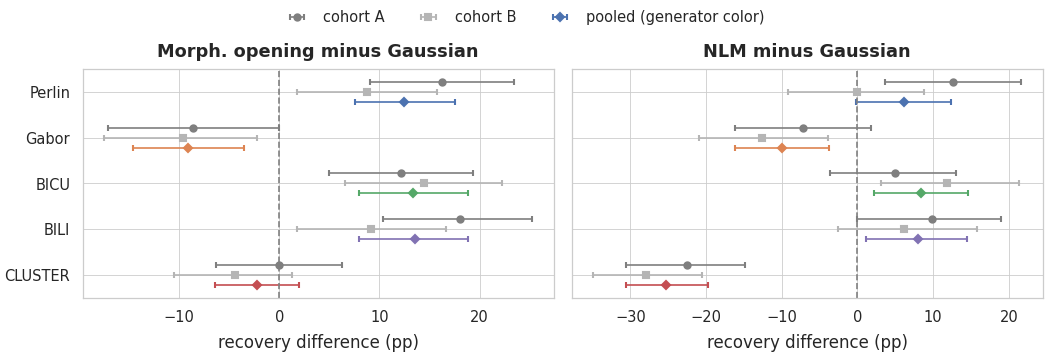

In [16]:
rows, forest, adv_pts, same_sign = [], [], {}, {}
for m in [MO, NL]:
    adv_pts[m] = {}
    for g in GENERATORS:
        d = pp(m, g) - pp(G_, g); bs_ = strat_boot(d[:, None], cohort_of, seed=SEED + 5)
        r = {"Denoiser minus Gaussian": DEN_LABEL[m], "Generator": GEN_LABEL[g]}
        for coh in ["A", "B", "pooled"]:
            pt = (d[cohort_of == coh].mean() if coh != "pooled" else d.mean()) * 100; lo, hi = pct_ci(bs_[coh][:, 0]) * 100
            r[f"{coh} (pp)"] = fmt_ci(pt, lo, hi); forest.append((m, g, coh, pt, lo, hi))
        adv_pts[m][g] = d.mean() * 100
        same_sign[(m, g)] = bool(np.sign(d[cohort_of == "A"].mean()) == np.sign(d[cohort_of == "B"].mean()))
        r["Same sign in A and B"] = same_sign[(m, g)]; rows.append(r)
display(pd.DataFrame(rows).set_index(["Denoiser minus Gaussian", "Generator"]))

fr = pd.DataFrame(forest, columns=["m", "g", "coh", "pt", "lo", "hi"])
fig, axs = plt.subplots(1, 2, figsize=(FULL_W, 2.3), sharey=True)
for a, m in zip(axs, [MO, NL]):
    for gi, g in enumerate(GENERATORS):
        for dy, coh, col, mk in [(-0.22, "A", "#7F7F7F", "o"), (0, "B", "#B5B5B5", "s"), (0.22, "pooled", GEN_COLOR[g], "D")]:
            rr = fr[(fr.m == m) & (fr.g == g) & (fr.coh == coh)].iloc[0]
            a.errorbar(rr.pt, gi + dy, xerr=[[rr.pt - rr.lo], [rr.hi - rr.pt]], fmt=mk, color=col, capsize=1.5, ms=3, lw=0.8,
                       label=(f"cohort {coh}" if coh != "pooled" else "pooled (generator color)") if (gi == 0 and m == MO) else None)
    a.axvline(0, color="gray", ls="--", lw=0.8); a.set_yticks(range(len(GENERATORS))); a.set_yticklabels([GEN_LABEL[g] for g in GENERATORS])
    a.set_ylim(len(GENERATORS) - 0.5, -0.5); a.set(title=f"{DEN_LABEL[m]} minus Gaussian", xlabel="recovery difference (pp)")
fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08), frameon=False)
plt.tight_layout()
export_fig(fig, "fig11_advantage_over_gaussian", "Recovery difference versus Gaussian within each generator (pp, 95% CI), by cohort")


### 11c. Full cohort table

Recovery % [95% CI] for cohort A, cohort B and pooled.


In [17]:
coh_tab = pd.DataFrame({(GEN_LABEL[g], k): {m: fmt_ci(est[k][cols.index((g, m))] * 100, CI[k][0, cols.index((g, m))] * 100, CI[k][1, cols.index((g, m))] * 100)
                                              for m in DENOISERS} for g in GENERATORS for k in ["A", "B", "pooled"]}).loc[DENOISERS]
with pd.option_context("display.max_columns", 20): display(coh_tab)
coh_tab.to_csv(f"{TAB_DIR}/supporting_cohort_recovery.csv")
MANIFEST.append({"file": f"{TAB_DIR}/supporting_cohort_recovery.csv", "type": "table (csv)", "description": "Recovery by cohort, generator and denoiser (supporting)"})


Perlin                     \
                                       A                  B   
Gaussian               48.6 [42.3, 55.0]  54.1 [47.6, 60.7]   
Median                 55.4 [48.6, 61.7]  53.7 [47.2, 60.3]   
Bilateral              48.6 [42.3, 55.0]  49.3 [42.8, 55.5]   
Non-Local Means        61.3 [54.5, 67.6]  54.1 [47.6, 60.3]   
Morphological Opening  64.9 [58.6, 70.7]  62.9 [56.8, 69.0]   
Average                51.8 [45.5, 58.1]  56.8 [50.7, 63.3]   

                                                      Gabor  \
                                  pooled                  A   
Gaussian               51.4 [46.8, 56.1]  58.1 [51.4, 64.4]   
Median                 54.5 [49.9, 59.0]  45.0 [38.3, 51.4]   
Bilateral              49.0 [44.3, 53.7]  43.2 [36.9, 49.5]   
Non-Local Means        57.6 [53.0, 61.9]  50.9 [44.1, 57.7]   
Morphological Opening  63.9 [59.4, 68.1]  49.5 [42.8, 56.3]   
Average                54.3 [49.9, 59.0]  52.3 [45.5, 59.0]   

                                                             \
                                       B             pooled   
Gaussian               58.1 [51.5, 64.2]  58.1 [53.7, 62.7]   
Median                 42.4 [36.2, 48.5]  43.7 [39.0, 48.3]   
Bilateral              38.4 [32.3, 45.0]  40.8 [36.1, 45.5]   
Non-Local Means        45.4 [38.9, 51.5]  48.1 [43.5, 52.8]   
Morphological Opening  48.5 [41.9, 55.0]  49.0 [44.3, 53.7]   
Average                57.2 [50.7, 63.3]  54.8 [50.3, 59.2]   

                                    BICU                     \
                                       A                  B   
Gaussian               46.8 [40.1, 53.2]  38.9 [32.3, 45.4]   
Median                 47.3 [40.5, 54.1]  45.9 [39.7, 52.4]   
Bilateral              51.8 [45.5, 58.1]  48.9 [42.4, 55.5]   
Non-Local Means        51.8 [45.5, 58.1]  50.7 [44.1, 57.2]   
Morphological Opening  59.0 [52.7, 65.8]  53.3 [46.7, 59.4]   
Average                48.6 [41.9, 55.4]  46.7 [40.2, 53.7]   

                                                       BILI  \
                                  pooled                  A   
Gaussian               42.8 [38.1, 47.5]  42.8 [36.0, 49.5]   
Median                 46.6 [41.9, 51.2]  46.8 [40.1, 53.6]   
Bilateral              50.3 [45.7, 55.0]  50.5 [44.1, 57.2]   
Non-Local Means        51.2 [46.6, 55.7]  52.7 [45.9, 59.0]   
Morphological Opening  56.1 [51.2, 60.8]  60.8 [54.1, 67.1]   
Average                47.7 [43.2, 52.3]  48.6 [41.9, 55.0]   

                                                             \
                                       B             pooled   
Gaussian               42.8 [36.7, 49.3]  42.8 [38.4, 47.5]   
Median                 42.8 [36.7, 49.3]  44.8 [40.1, 49.4]   
Bilateral              44.5 [38.0, 50.7]  47.5 [42.8, 51.9]   
Non-Local Means        48.9 [42.4, 55.5]  50.8 [45.9, 55.4]   
Morphological Opening  52.0 [45.4, 58.5]  56.3 [51.7, 60.8]   
Average                49.8 [43.2, 55.9]  49.2 [44.3, 53.9]   

                                 CLUSTER                                        
                                       A                  B             pooled  
Gaussian               82.4 [77.5, 87.4]  85.6 [81.2, 90.0]  84.0 [80.5, 87.1]  
Median                 68.0 [61.7, 74.3]  65.9 [59.8, 72.1]  67.0 [62.3, 71.4]  
Bilateral              76.1 [70.7, 81.5]  72.9 [67.2, 78.6]  74.5 [70.5, 78.3]  
Non-Local Means        59.9 [53.6, 66.2]  57.6 [51.1, 64.2]  58.8 [54.1, 63.4]  
Morphological Opening  82.4 [77.5, 87.4]  81.2 [76.0, 86.5]  81.8 [78.3, 85.4]  
Average                75.7 [69.8, 81.1]  75.1 [69.4, 80.3]  75.4 [71.4, 79.2]

### 11d. Dependence of the generator summary on the generator set

The equal-weight mean changes with the configurations included. Below, the same summary is computed for the first three generators (Perlin, Gabor, BICU) only, for comparison with Section 10. It is not a separate testing family.


In [18]:
summ3, best3, diff3, _ = gen_summary(["perlin", "gabor", "BICU"], SEED + 2)
display(pd.DataFrame({"Equal-weight mean, 3 generators (%)": summ3["Equal-weight mean (%)"], "Equal-weight mean, 5 generators (%)": summ["Equal-weight mean (%)"],
                      "Minimum observed, 3 (%)": summ3["Minimum observed (%)"], "Minimum observed, 5 (%)": summ["Minimum observed (%)"]}).round(1))
display(diff3)


,"Equal-weight mean, 3 generators (%)","Equal-weight mean, 5 generators (%)","Minimum observed, 3 (%)","Minimum observed, 5 (%)"
Gaussian,50.8,55.8,42.8,42.8
Median,48.3,51.3,43.7,43.7
Bilateral,46.7,52.4,40.8,40.8
Non-Local Means,52.3,53.3,48.1,48.1
Morphological Opening,56.3,61.4,49.0,49.0
Average,52.3,56.3,47.7,47.7


,Difference pp [unadjusted 95% CI]
Comparison (exploratory),
Morphological Opening minus Gaussian,"5.5 [2.1, 8.8]"
Morphological Opening minus Median,"8.1 [4.6, 11.5]"
Morphological Opening minus Bilateral,"9.6 [5.3, 13.9]"
Morphological Opening minus Non-Local Means,"4.0 [-0.1, 7.9]"
Morphological Opening minus Average,"4.1 [0.7, 7.3]"


### 11e. Paired distortion differences and distribution overlap

The ratio of each generator's saved L∞ to Perlin's on the same image, and the overlap of the L∞ distributions.


,Median Linf difference (0-255),Median ratio,Ratio IQR,Larger than Perlin (%)
Pair (same image),,,,
Gabor vs Perlin,0.25,1.04,0.75-1.44,52.11
BICU vs Perlin,5.75,1.96,1.10-6.72,78.71
BILI vs Perlin,5.25,1.83,1.07-5.85,77.16
CLUSTER vs Perlin,8.50,2.16,1.20-4.32,79.82


Perlin and Gabor saved attacks reach at most 79.7 (0-255 scale). Share above that, with no Perlin or Gabor counterpart: BICU 21%, BILI 20%, CLUSTER 6%


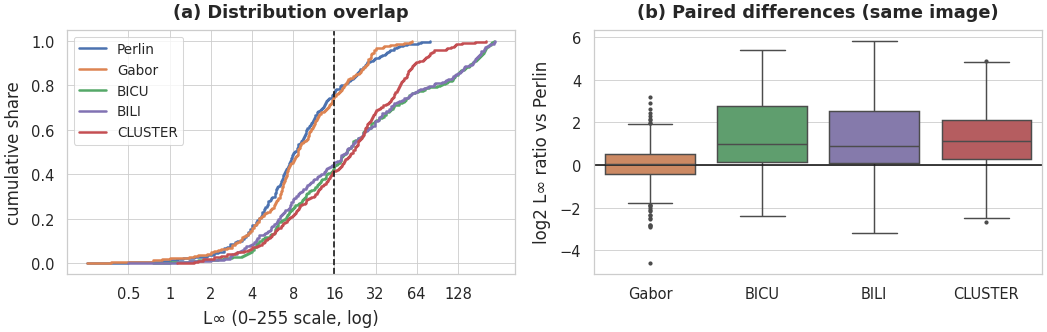

In [19]:
L_ = {g: R[g]["linf255"].to_numpy() for g in GENERATORS}
rows = []
for g in GENERATORS[1:]:
    ratio = np.log2(L_[g] / L_["perlin"])
    rows.append({"Pair (same image)": f"{GEN_LABEL[g]} vs Perlin", "Median Linf difference (0-255)": np.median(L_[g] - L_["perlin"]),
                 "Median ratio": 2 ** np.median(ratio), "Ratio IQR": f"{2**np.percentile(ratio,25):.2f}-{2**np.percentile(ratio,75):.2f}",
                 "Larger than Perlin (%)": (L_[g] > L_["perlin"]).mean() * 100})
display(pd.DataFrame(rows).set_index("Pair (same image)").round(2))
hi_pg = max(L_["perlin"].max(), L_["gabor"].max())
print(f"Perlin and Gabor saved attacks reach at most {hi_pg:.1f} (0-255 scale). Share above that, with no Perlin or Gabor counterpart: "
      + ", ".join(f"{GEN_LABEL[g]} {(L_[g] > hi_pg).mean()*100:.0f}%" for g in ["BICU", "BILI", "CLUSTER"]))

fig, ax = plt.subplots(1, 2, figsize=(FULL_W, 2.4))
for g in GENERATORS:
    s = np.sort(L_[g]); ax[0].step(s, np.arange(1, len(s) + 1) / len(s), where="post", color=GEN_COLOR[g], label=GEN_LABEL[g], lw=1.2)
ax[0].set_xscale("log"); ax[0].axvline(16, color="k", ls="--", lw=0.8)
ax[0].xaxis.set_major_locator(FixedLocator([0.5, 1, 2, 4, 8, 16, 32, 64, 128])); ax[0].xaxis.set_major_formatter(G_FMT); ax[0].xaxis.set_minor_locator(FixedLocator([]))
ax[0].set(xlabel="L∞ (0–255 scale, log)", ylabel="cumulative share", title="(a) Distribution overlap"); ax[0].legend(fontsize=6.5)
rl = pd.DataFrame({GEN_LABEL[g]: np.log2(L_[g] / L_["perlin"]) for g in GENERATORS[1:]}).melt(var_name="gen", value_name="lr")
sns.boxplot(data=rl, x="gen", y="lr", hue="gen", palette={GEN_LABEL[g]: GEN_COLOR[g] for g in GENERATORS}, legend=False, ax=ax[1], fliersize=1, linewidth=0.7)
ax[1].axhline(0, color="k", lw=0.8); ax[1].set(xlabel="", ylabel="log2 L∞ ratio vs Perlin", title="(b) Paired differences (same image)")
plt.tight_layout()
export_fig(fig, "fig12_distortion_overlap", "Saved L-infinity distributions (a) and paired log2 ratio versus Perlin on the same image (b)")


### 11f. Recovery by distortion bin

All saved attacks pooled (451 images × 5 generators) and binned by L∞. Pooling bins changes *both* the generator mix and the class mix within each bin, and rows from the same image are not independent, so this is shape only, with no intervals. It is not evidence that larger perturbations are easier to recover.


class and generator mix (%) per bin:


,CNV,DME,DRUSEN,NORMAL,perlin,gabor,BICU,BILI,CLUSTER,n
bin,,,,,,,,,,
<=4,6.0,3.0,73.0,18.0,31.0,29.0,11.0,16.0,12.0,226
4-8,16.0,10.0,46.0,28.0,28.0,26.0,16.0,17.0,13.0,534
8-16,26.0,26.0,20.0,28.0,25.0,26.0,17.0,15.0,18.0,512
16-32,19.0,57.0,4.0,20.0,15.0,21.0,20.0,18.0,26.0,461
>32,53.0,27.0,0.0,20.0,7.0,3.0,31.0,31.0,28.0,522


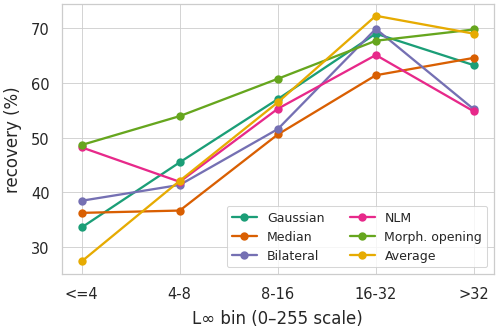

In [20]:
bins, labels = [0, 4, 8, 16, 32, 256], ["<=4", "4-8", "8-16", "16-32", ">32"]
long["bin"] = pd.cut(long["linf255"], bins=bins, labels=labels, include_lowest=True)
by_bin = pd.DataFrame({m: long.groupby("bin", observed=False)[m].apply(lambda s: s.astype(float).mean() * 100) for m in DENOISERS}).loc[labels]
mix_bin = pd.concat([pd.crosstab(long["bin"], long["true"], normalize="index").reindex(index=labels, columns=CLASSES) * 100,
                     pd.crosstab(long["bin"], long["gen"], normalize="index").reindex(index=labels, columns=GENERATORS) * 100], axis=1)
mix_bin["n"] = long["bin"].value_counts().reindex(labels)
print("class and generator mix (%) per bin:"); display(mix_bin.round(0))
fig, ax = plt.subplots(figsize=(COL_W, 2.4))
for m in DENOISERS: ax.plot(labels, by_bin[m], marker="o", ms=3, lw=1.1, color=DEN_COLOR[m], label=DEN_LABEL[m])
ax.set(xlabel="L∞ bin (0–255 scale)", ylabel="recovery (%)"); ax.legend(fontsize=6, ncol=2)
plt.tight_layout()
export_fig(fig, "fig13_recovery_by_distortion_bin", "Recovery by L-infinity bin, all generators pooled (descriptive; class and generator mix differ by bin)")


### 11g. Common-threshold subset

Images for which all five saved attacks have L∞ ≤ 16/255.
- **This restricts by threshold; it does not match distortion**, which can still differ between generators inside the subset.
- **The restriction changes the patient and class composition.**
- **Differences within the subset do not isolate perturbation structure**, and similar values do not show equivalence or that distortion explains the full-set differences.

No tests are reported for this subset.


In [21]:
within = np.all([R[g]["linf"].to_numpy() <= T16 for g in GENERATORS], axis=0)
print(f"common-threshold subset: n = {within.sum()} of {len(COMMON)}")
display(pd.DataFrame({"Full set (%)": R["perlin"]["true"].value_counts(normalize=True).reindex(CLASSES) * 100,
                      "Subset (%)": R["perlin"]["true"][within].value_counts(normalize=True).reindex(CLASSES) * 100}).round(0))
print("median L∞ (0-255) inside the subset:", {GEN_LABEL[g]: round(float(np.median(R[g]["linf255"][within])), 1) for g in GENERATORS})
display(pd.DataFrame({GEN_LABEL[g]: R[g][DENOISERS][within].astype(float).mean() * 100 for g in GENERATORS}).round(1))


common-threshold subset: n = 119 of 451


,Full set (%),Subset (%)
true,,
CNV,26.0,3.0
DME,27.0,2.0
DRUSEN,24.0,78.0
NORMAL,24.0,17.0


median L∞ (0-255) inside the subset: {'Perlin': 4.0, 'Gabor': 4.0, 'BICU': 5.9, 'BILI': 5.4, 'CLUSTER': 6.1}


,Perlin,Gabor,BICU,BILI,CLUSTER
Gaussian,29.4,35.3,28.6,30.3,62.2
Median,31.1,38.7,30.3,26.9,36.1
Bilateral,34.5,42.0,37.8,37.0,59.7
Non-Local Means,50.4,39.5,28.6,28.6,40.3
Morphological Opening,47.1,45.4,41.2,41.2,62.2
Average,22.7,28.6,25.2,27.7,45.4


### 11h. GEE sensitivity analysis

For each denoiser, a logistic model fitted by generalized estimating equations (GEE), with exchangeable correlation and clustering by image (each image appears once per generator):

`recovered ~ generator (Perlin = reference) + standardized log L∞ + class`

Odds ratios are **conditional associations** given the measured class and L∞. They are not causal effects and not changes in recovery percentage. Adjustment does not remove differences in search dimensionality or optimization behavior, and the large-L∞ tails of BICU, BILI and CLUSTER have little Perlin or Gabor counterpart. Convergence and warnings are reported. P-values are not emphasized.


clusters: 451 images; rows per cluster: [np.int64(5)]


,Converged,Within-image correlation,Warnings
Denoiser,,,
Gaussian,True,0.183,none
Median,True,0.162,none
Bilateral,True,0.201,none
Non-Local Means,True,0.157,none
Morphological Opening,True,0.161,none
Average,True,0.159,none


Term,+1 SD log L∞,BICU vs Perlin,BILI vs Perlin,CLUSTER vs Perlin,Gabor vs Perlin
Denoiser,,,,,
Average,1.20,0.63,0.69,2.71,1.02
Bilateral,0.82,1.31,1.11,4.61,0.64
Gaussian,1.23,0.58,0.58,5.00,1.33
Median,1.11,0.64,0.59,1.71,0.60
Morphological Opening,0.89,0.78,0.78,2.85,0.53
Non-Local Means,0.88,0.84,0.82,1.17,0.65


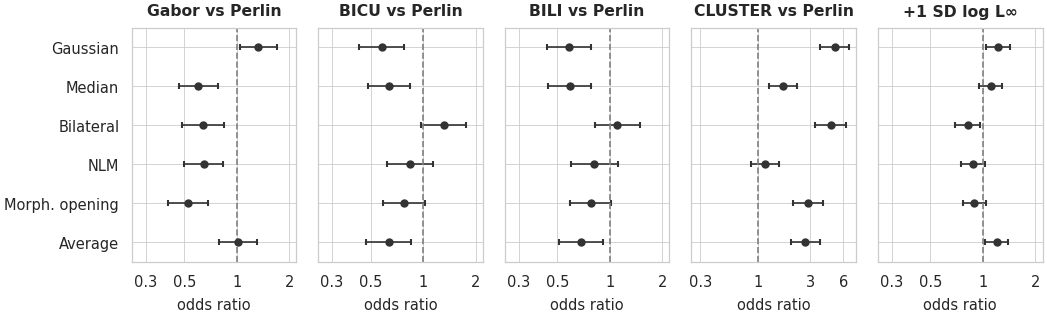

In [22]:
Lg = pd.concat([R[g].assign(gen=g, img=R[g].index) for g in GENERATORS], ignore_index=True)
lz = np.log(Lg["linf"].clip(lower=1e-4)); Lg["logLinf_z"] = (lz - lz.mean()) / lz.std()
print(f"clusters: {Lg['img'].nunique()} images; rows per cluster: {sorted(Lg.groupby('img').size().unique())}")
rows, fit_notes = [], []
for m in DENOISERS:
    Lg["y"] = Lg[m].astype(int)
    with warnings.catch_warnings(record=True) as wl:
        warnings.simplefilter("always")
        res = smf.gee('y ~ C(gen, Treatment("perlin")) + logLinf_z + C(true)', "img", data=Lg,
                      family=sm.families.Binomial(), cov_struct=sm.cov_struct.Exchangeable()).fit()
    fit_notes.append({"Denoiser": m, "Converged": bool(getattr(res, "converged", np.nan)), "Within-image correlation": round(float(res.cov_struct.dep_params), 3),
                      "Warnings": "; ".join(sorted({str(w.message)[:80] for w in wl})) or "none"})
    ci = res.conf_int()
    for key, lab in [([k for k in res.params.index if f"[T.{g}]" in k][0], f"{GEN_LABEL[g]} vs Perlin") for g in GENERATORS[1:]] + [("logLinf_z", "+1 SD log L∞")]:
        rows.append({"Denoiser": m, "Term": lab, "Odds ratio": np.exp(res.params[key]), "CI low": np.exp(ci.loc[key, 0]), "CI high": np.exp(ci.loc[key, 1])})
display(pd.DataFrame(fit_notes).set_index("Denoiser"))
gee = pd.DataFrame(rows); display(gee.round(2).set_index(["Denoiser", "Term"]).unstack("Term")["Odds ratio"])

terms = [f"{GEN_LABEL[g]} vs Perlin" for g in GENERATORS[1:]] + ["+1 SD log L∞"]
fig, axs = plt.subplots(1, len(terms), figsize=(FULL_W, 2.3), sharey=True)
for a, term in zip(axs, terms):
    t = gee[gee["Term"] == term].set_index("Denoiser").loc[DENOISERS]; yy = np.arange(len(t))
    a.errorbar(t["Odds ratio"], yy, xerr=[t["Odds ratio"] - t["CI low"], t["CI high"] - t["Odds ratio"]], fmt="o", color="#333", ms=3, capsize=1.5, lw=0.8)
    a.axvline(1, color="gray", ls="--", lw=0.8); a.set_xscale("log")
    lo_x, hi_x = min(0.25, t["CI low"].min() * 0.85), max(2.2, t["CI high"].max() * 1.15)
    cand = [0.3, 0.5, 1, 2] if hi_x <= 2.5 else [0.3, 1, 3, 6]
    a.set_xticks([v for v in cand if lo_x <= v <= hi_x]); a.xaxis.set_major_formatter(G_FMT); a.xaxis.set_minor_locator(FixedLocator([])); a.set_xlim(lo_x, hi_x)
    a.set_yticks(yy); a.set_yticklabels([DEN_LABEL[m] for m in DENOISERS]); a.set_ylim(len(DENOISERS) - 0.5, -0.5)
    a.set_title(term, fontsize=7.5); a.set_xlabel("odds ratio", fontsize=7)
plt.tight_layout()
export_fig(fig, "fig14_gee_odds_ratios", "GEE sensitivity analysis: conditional odds ratios with 95% CIs (exploratory)")
mark_done("11")


## 12. Conclusions and limitations

The summary below is computed from the analyses above.


In [23]:
def line(s): print("- " + s)
lo_c, hi_c = REC.stack().idxmin(), REC.stack().idxmax()
print("GENERATOR-DEPENDENT RECOVERY")
line(f"Recovery of the {len(COMMON)} valid attacked images ranges from {REC.values.min():.1f}% ({DEN_LABEL[lo_c[0]]}, {GEN_LABEL[lo_c[1]]}) "
     f"to {REC.values.max():.1f}% ({DEN_LABEL[hi_c[0]]}, {GEN_LABEL[hi_c[1]]}).")
line(f"Cochran's Q across the five generators: Holm-adjusted p < 0.05 for {int((t5['Holm p'] < 0.05).sum())} of 6 denoisers "
     f"(largest adjusted p {fmt_p(t5['Holm p'].max())}).")
line(f"Pairwise generator comparisons: {int((t6['Holm p'] < 0.05).sum())} of 30 Holm-adjusted p < 0.05 "
     f"(" + ", ".join(f"{DEN_LABEL[m]} {int((t6.loc[m, 'Holm p'] < 0.05).sum())}/10" for m in SELECTED) + ").")
easy = REC.mean().idxmax()
line(f"{GEN_LABEL[easy]} attacks had the highest mean recovery across denoisers ({REC.mean().max():.1f}%) despite a median saved L∞ of "
     f"{R[easy]['linf255'].median():.1f} (0-255 scale), so recovery is not simply a function of attack size.")

print("\nRELATIVE DENOISER PERFORMANCE")
line("Highest observed recovery per generator: " + ", ".join(f"{GEN_LABEL[g]} {DEN_LABEL[REC[g].idxmax()]} ({REC[g].max():.1f}%)" for g in GENERATORS) + ".")
for m in adv_pts:
    pos = [GEN_LABEL[g] for g in GENERATORS if adv_pts[m][g] > 0]; neg = [GEN_LABEL[g] for g in GENERATORS if adv_pts[m][g] < 0]
    line(f"{DEN_LABEL[m]} versus Gaussian (pooled point estimates): ahead under {', '.join(pos) or 'none'}; behind under {', '.join(neg) or 'none'}.")
for k, d in contr.items(): line(f"{k}: {fmt_ci(*d['pooled'])} pp (exploratory).")
line(f"Highest equal-weight mean across the five tested generators: {best} ({summ.loc[best, 'Equal-weight mean (%)']:.1f}%, CI {summ.loc[best, '95% CI']}); "
     f"minimum observed aggregate recovery {summ.loc[best, 'Minimum observed (%)']:.1f}%. Comparisons with other denoisers are exploratory and unadjusted (Section 10).")

print("\nCLASS-SPECIFIC DIFFERENCES")
cnt_low = pd.Series(low_cls).value_counts()
line("Lowest-recovery class per denoiser (mean over generators): " + ", ".join(f"{c} for {n}" for c, n in cnt_low.items()) + " of 6 denoisers.")

print("\nCLEAN-IMAGE COST")
line(f"Clean-accuracy loss on the {n_clean:,} test images ranges from {clean_loss.min():.1f} pp ({clean_loss.idxmin()}) to {clean_loss.max():.1f} pp "
     f"({clean_loss.idxmax()}), against a {base:.1f}% baseline (earlier PNG-based evaluation).")
line(f"On the {len(ok_new)} cohort images evaluated by both pipelines, clean accuracies differ by at most {bridge_max:.1f} pp ({bridge_arg}); "
     f"predictions are identical for {', '.join(bridge_exact) or 'no denoiser'}.")
line(f"Paired clean-accuracy difference, {two[0]} minus {two[1]}: {dd.mean()*100:+.1f} pp [{dlo:+.1f}, {dhi:+.1f}].")

print("\nCOHORT CONSISTENCY  (consistency check, not external validation)")
line(f"{int((np.abs(dAB) <= 5).sum())} of {len(cols)} cells differ by at most 5 pp between cohorts; the largest difference is "
     f"{np.abs(dAB).max():.1f} pp ({DEN_LABEL[cols[int(np.argmax(np.abs(dAB)))][1]]} under {GEN_LABEL[cols[int(np.argmax(np.abs(dAB)))][0]]}).")
line(f"Highest observed denoiser per generator agrees between cohorts for {sum(topA[g] == topB[g] for g in GENERATORS)} of {len(GENERATORS)} generators.")
line(f"Advantage over Gaussian has the same sign in both cohorts for {sum(same_sign.values())} of {len(same_sign)} denoiser-generator combinations.")
mark_done("12")


GENERATOR-DEPENDENT RECOVERY
- Recovery of the 451 valid attacked images ranges from 40.8% (Bilateral, Gabor) to 84.0% (Gaussian, CLUSTER).
- Cochran's Q across the five generators: Holm-adjusted p < 0.05 for 6 of 6 denoisers (largest adjusted p 3.0e-04).
- Pairwise generator comparisons: 13 of 30 Holm-adjusted p < 0.05 (Morph. opening 5/10, NLM 2/10, Gaussian 6/10).
- CLUSTER attacks had the highest mean recovery across denoisers (73.6%) despite a median saved L∞ of 21.8 (0-255 scale), so recovery is not simply a function of attack size.

RELATIVE DENOISER PERFORMANCE
- Highest observed recovery per generator: Perlin Morph. opening (63.9%), Gabor Gaussian (58.1%), BICU Morph. opening (56.1%), BILI Morph. opening (56.3%), CLUSTER Gaussian (84.0%).
- Morph. opening versus Gaussian (pooled point estimates): ahead under Perlin, BICU, BILI; behind under Gabor, CLUSTER.
- NLM versus Gaussian (pooled point estimates): ahead under Perlin, BICU, BILI; behind under Gabor, CLUSTER.
- Contrast A:

**Scope.** This is a paired empirical evaluation of how recovery from non-adaptive decision-based attacks, and the relative performance of six classical denoisers, vary across five tested generator configurations on one OCT classifier, together with the denoisers' clean-image cost. It does not propose a new defense. It does not establish clinical safety or deployment readiness, causal effects of perturbation structure or frequency, adaptive robustness, or the general superiority of any denoiser.

**Limitations and unverified points.**
- **Confounded comparisons.** The configurations differ at once in search dimensionality (3, 6, 48, 48 and 48 parameters), achieved distortion, color structure, and recorded query behavior. BICU, BILI and CLUSTER perturb each color channel independently; Perlin and Gabor do not. No analysis here separates these factors.
- **Limited design.** One classifier, one seed per configuration, and a non-adaptive attacker. Seed-to-seed variability was not measured.
- **Helper code not available.** `recognition_precision.py`, `denoiser_precision.py` and the run-time `Util.py` were not provided. The model each step loads, its preprocessing, the denoiser settings (including what Average combines) and whether every denoiser preserves floating-point precision are unconfirmed. Non-Local Means probably operates on 8-bit input.
- **Checkpoint identity.** The original predictions match the v2.1 reference, and the adversarial verification agreed with the attack on every image. That is consistent with one model throughout, but the model used for denoised predictions is not independently verified.
- **Batch behavior.** An attack that finds no adversarial would be skipped without any exported row; none occurred in these runs (Section 2). Per-image arrays are overwritten and not retained.
- **Gabor query counts.** A noticeable share of Gabor runs recorded fewer than 190 queries. The code suggests a cause, but no log confirms it, and Gabor may have received less search than the other generators.
- **Clean-cost pipeline.** Clean costs come from the earlier PNG-based evaluation of the 1,000 test images. On the 480 cohort images evaluated by both pipelines, clean accuracies agree to within 1 percentage point for every denoiser (Section 5), but the other 520 images were not re-evaluated under the revised pipeline.
- **Cohort sampling.** How the attacked images were selected is not documented.
- **Validation–test gap.** Validation accuracy (85.1%) is below test accuracy (93.8%); available records do not explain the gap.


## 13. Execution and output-file summary


In [24]:
status = []
for k, v in FILES.items():
    for f in (v if isinstance(v, tuple) else (v,)):
        p = f"{DATA_DIR}/{f}"; status.append({"Input file": f, "Available": p.startswith("http") or os.path.exists(p)})
display(pd.DataFrame(status).set_index("Input file"))

expected_sections = ["2", "3", "4", "5", "6", "7", "8", "9", "10", "11", "12"]
missing_sections = [s for s in expected_sections if s not in COMPLETED]
cs = pd.DataFrame(CHECKS)["status"].value_counts().to_dict()
print(f"sections completed in this run: {', '.join(COMPLETED)}" + (f" | NOT completed: {', '.join(missing_sections)}" if missing_sections else ""))
print(f"integrity checks: {len(CHECKS)} run; {cs.get('PASS', 0)} passed, {cs.get('FLAG', 0)} flagged, {cs.get('FAIL', 0)} failed")

man = pd.DataFrame(MANIFEST + [{"file": f"{OUT_DIR}/manifest.csv", "type": "manifest", "description": "This list of output files"}])
man["exists"] = man["file"].map(os.path.exists); man.loc[man["type"] == "manifest", "exists"] = True
man.to_csv(f"{OUT_DIR}/manifest.csv", index=False)
print(f"output files: {len(man)} listed in {OUT_DIR}/manifest.csv; missing on disk: {int((~man['exists']).sum())}")
with pd.option_context("display.max_rows", 80, "display.max_colwidth", 90): display(man[["file", "type", "description"]])
print(f"environment: Python {platform.python_version()}, numpy {np.__version__}, pandas {pd.__version__}, statsmodels {statsmodels.__version__}, "
      f"scipy {scipy.__version__}, matplotlib {matplotlib.__version__}, seaborn {sns.__version__}")
print("Results above are recomputed from the input files in this run. Not verified here: the items listed under Limitations (Section 12).")


,Available
Input file,
test_predictions_1.csv,True
run_info_1.json,True
New_All_Clean_OCT_2_.xlsx,True
240_PNG_Perlin.xlsx,True
More_240_PNG_Perlin_1.xlsx,True
240_PNG_Gabor.xlsx,True
More_240_PNG_Gabor.xlsx,True
240_PNG_BICU.xlsx,True
More_240_PNG_BICU.xlsx,True


sections completed in this run: 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12
integrity checks: 117 run; 108 passed, 9 flagged, 0 failed
output files: 44 listed in outputs/manifest.csv; missing on disk: 0


,file,type,description
0,outputs/figures/fig01_baseline_confusion_matrix.pdf,figure (pdf),"Baseline confusion matrix, InceptionV3 v2.1, 1,000 test images (accuracy 93.8%)"
1,outputs/figures/fig01_baseline_confusion_matrix.png,figure (png),"Baseline confusion matrix, InceptionV3 v2.1, 1,000 test images (accuracy 93.8%)"
2,outputs/tables/table1_baseline_class_metrics.csv,table (csv),"Baseline per-class performance, InceptionV3 v2.1 (1,000 test images; % with patient-cl..."
3,outputs/tables/table1_baseline_class_metrics.tex,table (tex),"Baseline per-class performance, InceptionV3 v2.1 (1,000 test images; % with patient-cl..."
4,outputs/tables/table2_attack_characteristics.csv,table (csv),Saved attack outputs by generator (n = 451 images each; Linf on the 0-255 scale; media...
5,outputs/tables/table2_attack_characteristics.tex,table (tex),Saved attack outputs by generator (n = 451 images each; Linf on the 0-255 scale; media...
6,outputs/figures/fig02_attack_characteristics.pdf,figure (pdf),"Saved attack outputs: (a) L-infinity distribution, (b) share within 16/255 by class, (..."
7,outputs/figures/fig02_attack_characteristics.png,figure (png),"Saved attack outputs: (a) L-infinity distribution, (b) share within 16/255 by class, (..."
8,outputs/tables/table3_clean_accuracy_loss.csv,table (csv),"Clean accuracy and loss after denoising, 1,000 test images (baseline 93.8%; paired, pa..."
9,outputs/tables/table3_clean_accuracy_loss.tex,table (tex),"Clean accuracy and loss after denoising, 1,000 test images (baseline 93.8%; paired, pa..."


environment: Python 3.12.3, numpy 2.0.2, pandas 2.2.2, statsmodels 0.14.4, scipy 1.14.1, matplotlib 3.10.0, seaborn 0.13.2
Results above are recomputed from the input files in this run. Not verified here: the items listed under Limitations (Section 12).


### Download the outputs

Zips the `outputs/` folder (figures, tables and manifest). In Colab the zip downloads automatically.

In [25]:
import shutil
archive = shutil.make_archive(OUT_DIR, "zip", OUT_DIR)
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(archive)
else:
    print(f"outputs zipped to {archive}")

outputs zipped to /home/claude/repo/oct-denoising-study/outputs.zip
